# Explication du projet

Pour atteindre son objectif de ville neutre en émissions de carbone en 2050, la ville de Seattle souhaite modéliser les consommations énergétiques ainsi que les émissions en gaz à effet de serre des bâtiments non destinés à l’habitation. L'objectif principal sera de mettre en place un modèle de prédiction de ces deux variables à partir de données structurelles liées aux batiments. Un objectif secondaire sera d'étudier l'impact de la variable ENERGYSTAR sur les résultats de prédictions afin de déterminer s'il est nécéssaire de continuer à calculer ce score qui est compliqué à calculer. Le présent notebook sera dédié à l'analyse exploratoire des données ainsi qu'aux premières étapes de nettoyage et de création de nouvelles caractéristiques. 

# Sommaire

- [3 Import](#Import-des-bibliothèques-et-des-données)
- [4 Exploration du fichier](#Exploration-du-fichier)
- [5 Définition des variables à prédire](#Définition-des-variables-à-prédire)
- [6 Première séléction des variables à garder](#Première-selection-des-variables-à-garder)
- [7 Filtre de la table](#Filtre-de-la-table)
- [8 Analyse du taux de valeurs manquantes](#Analyse_du-taux-de-valeurs-manquantes)
- [9 Premières analyses des données](#Premières-analyses-des-données)
- [10 Feature engineering](#Feature-engineering)
- [11 Deuxième analyse des données](#Deuxièeme-analyse-des-données)
- [12 Selection finale des features](#Selection-finale-des-features)
- [13 Conclusions](#Conclusion)



# Import des bibliothèques et des données

**Biliothèques**

In [1]:
# Manipulation de données
import pandas as pd
import missingno as msno
import numpy as np

# Représentation graphique
import matplotlib.pyplot as plt
import seaborn as sns

# Librairie sickit learn
from sklearn.preprocessing import MinMaxScaler

# Mapnipulation d'expressions regulières
import re

**Données**

In [2]:
# Chargement des données
Data_brute = pd.read_csv("../Data/2016_Building_Energy_Benchmarking.csv")

In [3]:
# Copie des données
Data = Data_brute.copy()

# Exploration du fichier

Une première phase d'exploration va être effectuée pour déterminer le nombre d'observations et de variables inclues dans le jeu de données. Cette première phase permettra également d'identifier les différents types de variables et leur signification.

In [4]:
# Visualisation des 5 premières lignes du fichier 
Data.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [5]:
# Nombre de variables et d'observations
Data.shape

(3376, 46)

In [6]:
# Calcule du nombre de variables par type
Data.dtypes.value_counts()

float64    22
object     15
int64       8
bool        1
Name: count, dtype: int64

In [7]:
# Affichage des noms de toutes les variables du jeu de données
for i in Data.columns:
    print(i)

OSEBuildingID
DataYear
BuildingType
PrimaryPropertyType
PropertyName
Address
City
State
ZipCode
TaxParcelIdentificationNumber
CouncilDistrictCode
Neighborhood
Latitude
Longitude
YearBuilt
NumberofBuildings
NumberofFloors
PropertyGFATotal
PropertyGFAParking
PropertyGFABuilding(s)
ListOfAllPropertyUseTypes
LargestPropertyUseType
LargestPropertyUseTypeGFA
SecondLargestPropertyUseType
SecondLargestPropertyUseTypeGFA
ThirdLargestPropertyUseType
ThirdLargestPropertyUseTypeGFA
YearsENERGYSTARCertified
ENERGYSTARScore
SiteEUI(kBtu/sf)
SiteEUIWN(kBtu/sf)
SourceEUI(kBtu/sf)
SourceEUIWN(kBtu/sf)
SiteEnergyUse(kBtu)
SiteEnergyUseWN(kBtu)
SteamUse(kBtu)
Electricity(kWh)
Electricity(kBtu)
NaturalGas(therms)
NaturalGas(kBtu)
DefaultData
Comments
ComplianceStatus
Outlier
TotalGHGEmissions
GHGEmissionsIntensity


Le jeu de données contient 3376 observations caractérisées par 46 variables fournissant différents type d'information qui seront étudiée de façon plus approfondie dans les sections suivantes. 

# Définition des variables à prédire

Le jeu de données contient un certains nombre de variables liées au profil énergétique des propriétés ayant été établi suite à des relevés datant de 2016. Parmi ces variables, on retrouve:

- **SiteEUIWN(kBtu/sf)** : L'intensité d'utilisation énergétique normalisée (WN) est l'énergie utilisée par le site divisée par la surface brute de plancher. Elle est ajustée en fonction des conditions climatiques moyennes sur 30 ans et mesurée en milliers de British thermal units (kBtu) par pied carré
- **SiteEUI(kBtu/sf)** : L'intensité d'utilisation énergétique (EUI) est l'énergie utilisée par le site divisée par sa surface brute. L'EUI est mesurée en milliers de British thermal units (kBtu) par pied carré.
- **SiteEnergyUse(kBtu)** = Quantité annuelle d'énergie consommée par la propriété à partir de toutes les sources d'énergie.
- **SiteEnergyUseWN(kBtu)** : Quantité annuelle d'énergie consommée par la propriété à partir de toutes les sources d'énergie, ajustée selon les conditions climatiques moyennes sur 30 ans.
-  **SourceEUIWN(kBtu/sf)** : L'intensité d'utilisation énergétique source (EUI) est l'énergie utilisée par la source divisée par la surface brute du bâtiment, ajustée selon les conditions climatiques moyennes sur 30 ans.
- **SourceEUI(kBtu/sf)** :  L'intensité d'utilisation énergétique source (EUI) est l'énergie utilisée par la source divisée par la surface brute du bâtiment. Elle inclut les pertes liées à la génération, la transmission et la distribution de l'énergie.
- **Electricity(kWh)** : Quantité annuelle d'électricité consommée sur place par la propriété, y compris l'électricité achetée du réseau et générée par les systèmes renouvelables sur place, mesurée en kilowattheures (kWh).
- **SteamUse(kBtu)** : Quantité annuelle de vapeur consommée par la propriété, mesurée en milliers de British thermal units (kBtu).
- **NaturalGas(therms)** : Quantité annuelle de gaz naturel fourni par les services publics et consommée par la propriété, mesurée en thermes.
- **Electricity(kBtu)** : Quantité annuelle d'électricité consommée sur place par la propriété, mesurée en milliers de British thermal units (kBtu).
- **NaturalGas(kBtu)** :  Quantité annuelle de gaz naturel fourni par les services publics et consommée par la propriété, mesurée en milliers de British thermal units (kBtu).
- **TotalGHGEmissions** :  La quantité totale d'émissions de gaz à effet de serre, incluant le dioxyde de carbone, le méthane et les oxydes d'azote, libérée dans l'atmosphère en raison de la consommation d'énergie sur la propriété, mesurée en tonnes métriques d'équivalent dioxyde de carbone. Ce calcul utilise les facteurs d'émissions spécifiques des services publics définis par la loi de 2023 sur les performances d'émissions des bâtiments.
- **GHGEmissionsIntensity** :  Les émissions totales de gaz à effet de serre divisées par la surface brute de plancher de la propriété, mesurées en kilogrammes d'équivalent dioxyde de carbone par pied carré.

Les variables qui seront modélisées dans ce projet : **SiteEnergyUse(kBtu)** et **TotalGHGEmissions** 

In [8]:
# Définition des deux variables à modéliser
Variable_cible1 = 'SiteEnergyUse(kBtu)'
Variable_cible2 = 'TotalGHGEmissions'

# Première selection des variables à garder

In [9]:
# Initialisation d'une liste contenant les features à garder pour la phase de modélisation
Candidate_features  = Data.columns.values.tolist()

## Exploration des variables catégorielles

On peut explorer les différentes variables catégorielles et examiner le nombre de catégories qu'elles contiennent afin d'identifier celles qui n'apporteront pas d'informations utiles pour un modèle d'apprentissage automatique. C'est par exemple le cas 

- des variables correspondant à un identifiant unique
- des variables possédant un nombre de catégorie proches du nombre d'observation et qui auront de ce fait des effectifs très faibles. Ces variables sont difficilement exploitable. Elles peuvent introduire du bruit, et n'apporte pas de structure exploitable à un modèle d'apprentissage. De plus, ces variables entrainent souvent un surapprentissage du fait que le modèle apprendra des spécificités et aura ainsi du mal à généraliser.
- des variables qui n'apportent aucune variabilité à l'analyse, telles que celles contenant une seule catégorie. 

Ces variables avec valeurs uniques ou représentant des identifiants ne seront pas utiles pour les modèles. Cette exploration est essentielle pour réduire la dimensionnalité des données et se concentrer sur les variables réellement pertinentes.

In [10]:
# Affichage du nombre de catégorie par variable 
Data.select_dtypes(include=['object', 'category', 'bool']).nunique()

BuildingType                        8
PrimaryPropertyType                24
PropertyName                     3362
Address                          3354
City                                1
State                               1
TaxParcelIdentificationNumber    3268
Neighborhood                       19
ListOfAllPropertyUseTypes         466
LargestPropertyUseType             56
SecondLargestPropertyUseType       50
ThirdLargestPropertyUseType        44
YearsENERGYSTARCertified           65
DefaultData                         2
ComplianceStatus                    4
Outlier                             2
dtype: int64

- Les variables **PropertyName**, **Address**, **TaxParcelIdentificationNumber** sont des caractéristique qu'on retrouve de manière quasi unique dans le jeu de données. Elle ne vont pas permettre aux algorithme de machine learning de dégager des pattern d'apprentissage. On ne gardera donc pas ces variables. 
- Les variables **City** et **State** ne varient pas et n'apporteront pas d'informations utiles aux algorithme de machine learning.

In [11]:
# Stockage des variables à retirer dans une liste
Features_to_remove = ['PropertyName', 'Address', 'TaxParcelIdentificationNumber',
                     'City', 'State', 'ListOfAllPropertyUseTypes']

## Exploration des variables numériques

Pour les variables numériques, l'objectif sera principalement dans un premier temps d'examiner les noms de ces variables afin d'identifier celles qui pourraient correspondre à des identifiants uniques qui n'apportent comme expliqué précédemment aucune information utile pour l'analyse ou la modélisation, car ils ne varient pas en fonction des autres variables. Dans une deuxième étape, après les différents filtres appliqués, on pourra également s'intéresser aux quantités de valeurs manquantes par variables pour identifier les variables qui auront trop de valeurs manquantes pour être exploitées telles quelles. 

In [12]:
# Affichage des type float et int de chacune des variables numériques
Data.select_dtypes(include=['float', 'int']).dtypes

OSEBuildingID                        int64
DataYear                             int64
ZipCode                            float64
CouncilDistrictCode                  int64
Latitude                           float64
Longitude                          float64
YearBuilt                            int64
NumberofBuildings                  float64
NumberofFloors                       int64
PropertyGFATotal                     int64
PropertyGFAParking                   int64
PropertyGFABuilding(s)               int64
LargestPropertyUseTypeGFA          float64
SecondLargestPropertyUseTypeGFA    float64
ThirdLargestPropertyUseTypeGFA     float64
ENERGYSTARScore                    float64
SiteEUI(kBtu/sf)                   float64
SiteEUIWN(kBtu/sf)                 float64
SourceEUI(kBtu/sf)                 float64
SourceEUIWN(kBtu/sf)               float64
SiteEnergyUse(kBtu)                float64
SiteEnergyUseWN(kBtu)              float64
SteamUse(kBtu)                     float64
Electricity

La variable OSEBuildingType corresponds a un identifiant unique et n'apportera pas d'information utiles pour les algorithme de machine learning. 

De plus, plusieurs variables numériques dans le jeu de données représentent en réalité des catégories, et non des données qui peuvent être traitées de manière quantitative. C'est le cas par exemple de ZipCode, CouncilDistrictCode et Comments, qui sont des identifiants ou des catégories qui ne doivent pas être considérés comme des variables continues à des fins d'analyse ou de modélisation." Ces variables seront donc converties en variables catégorielles.

Par ailleurs, dans le jeu de données, certaines variables ne seront pas disponibles lors de la phase de prédiction des données futures, ce qui pourrait introduire un risque de data leakage si elles sont utilisées pour l'entraînement du modèle. Afin d'éviter toute fuite d'information nous eliminerons donc également les variables suivantes:
- SiteEUI(kBtu/sf)                   
- SiteEUIWN(kBtu/sf)                
- SourceEUI(kBtu/sf)                 
- SourceEUIWN(kBtu/sf)              
- SiteEnergyUseWN(kBtu)              
- SteamUse(kBtu)                     
- Electricity(kWh)                  
- Electricity(kBtu)                  
- NaturalGas(therms)                 
- NaturalGas(kBtu)                   
- GHGEmissionsIntensity   

In [13]:
# Conversion de certaines variables de type numérique en type object
Data[['Comments', 'ZipCode', 'CouncilDistrictCode']]= Data[['Comments', 'ZipCode', 'CouncilDistrictCode']].astype(object)

# Affichage du nombre de catégorie par variable 
Data[['Comments', 'ZipCode', 'CouncilDistrictCode']].nunique()

Comments                0
ZipCode                55
CouncilDistrictCode     7
dtype: int64

La variable Comments ne contient en réalité aucune donnée et peut donc également être exlue des analyses.

In [14]:
# Stockage des variables entrainant de la fuite de données dans une liste 
Features_conso = ['SiteEUI(kBtu/sf)','SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)',
                  'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)', 
                  'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)',
                  'NaturalGas(kBtu)', 'GHGEmissionsIntensity']

# Ajout des nouvelles variables à retirer dans la liste des variables à exclure
Features_to_remove = Features_to_remove + ['OSEBuildingID', 'Comments' ] + Features_conso

# Filtre de la table

Dans ce projet l'objectif est de modéliser les consommation énergétique des propriétés non résidentielles. On ne va donc s'intéresser ici qu'aux propriétées non destinées à l'habitation et retirer les autres du jeu de données. Il faut aussi s'assurer qu'aucune proporiété ne soit présente en plusieurs exemplaires. Enfin les propriétés non conformes selon les relevés seront également écartées du jeu de données.

In [15]:
# Copie de la daataframe
Data_2 = Data.copy()

## Filtre sur les propriétés dupliquées

In [16]:
# Affichage du nombre de propriétées dupliquées sur la base de leur identifiant OSE
Data.duplicated('OSEBuildingID').sum()

0

Aucune propriété n'apparait dupliquée sur ce jeux de données

## Filtre sur les propriétés non destinées à l'habitation

Afin de retirer les propriétés non résidentilles on va s'intéresser aux différentes variables indiquant leur type et les usages qui leur sont associés.

In [17]:
# Visualisation des différentes catégories de la variable BuildingType
Data_2['BuildingType'].value_counts()

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

Plusieurs catégories sont clairement indiqués comme non destinés à l'habitation:
- NonResidential 
- Nonresidential WA
- Nonresidential COS

Les catégories Multifamily, correspondent a des propriétés résidentielles.

Pour mieux comprendre à quoi corresdpond la catégorie SPS-District K-12 on va regarder les utilisation associées à cette catégorie de propriété. 

In [18]:
# Visualisation des différents types d'utilisation associés à SPS-District K-12 School de la variable BuildingType
Data_2[Data_2['BuildingType']=='SPS-District K-12'][['BuildingType', 'PrimaryPropertyType', 
                                      'LargestPropertyUseType', 'SecondLargestPropertyUseType',
                                     'ThirdLargestPropertyUseType']].drop_duplicates()

,BuildingType,PrimaryPropertyType,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType
22,SPS-District K-12,K-12 School,K-12 School,NaN,NaN
116,SPS-District K-12,K-12 School,K-12 School,Parking,NaN
632,SPS-District K-12,Other,Other,"Repair Services (Vehicle, Shoe, Locksmith, etc)",Restaurant
1007,SPS-District K-12,Other,Other,NaN,NaN


La catégorie SPS-District K-12 semble liée à la scolarité et ne contient aucune mention d'une utilisation de logement.

In [19]:
# Filtre de la dataframe pour ne conserver que les catétories faisant référence à des propriétés non destinées à l'habitation
Data_2= Data_2[Data_2['BuildingType'].isin(['NonResidential', 'Nonresidential COS',
                                     'SPS-District K-12', 'Campus', 'Nonresidential WA'])]

On peut vérifier que les propriétés restantes ne sont pas associées à des catégorie liées à une forme d'habitation en explorant les différentes catégories restantes des variables PrimaryPropertyType et LargestPropertyUtilisationType

In [20]:
# Visualisation des différentes catégories de la variable PrimaryPropertyType
print(Data_2['PrimaryPropertyType'].value_counts())

PrimaryPropertyType
Small- and Mid-Sized Office    292
Other                          250
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             114
Retail Store                    91
Hotel                           76
Worship Facility                71
Distribution Center             53
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      24
Residence Hall                  21
Senior Care Community           20
Refrigerated Warehouse          12
Restaurant                      12
Hospital                        10
Laboratory                      10
Low-Rise Multifamily             3
Office                           3
Name: count, dtype: int64


On remarque qu'on a deux types qui semblent correspondre à de l'habitation 
- Residence Hall 
- Low-Rise Multifamily

On va regarder plus en détail à quoi correspondent ces propriétés

In [21]:
# Visualisation des propriétés dont le type semble correspondre à de l'habitation
Data_2[Data_2['PrimaryPropertyType'].isin(['Residence Hall','Low-Rise Multifamily'])][
   ['BuildingType', 'PrimaryPropertyType', 'LargestPropertyUseType', 'SecondLargestPropertyUseType',
    'ThirdLargestPropertyUseType', 'PropertyName']]

,BuildingType,PrimaryPropertyType,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,PropertyName
115,NonResidential,Residence Hall,Residence Hall/Dormitory,NaN,NaN,Emerson Hall
186,NonResidential,Residence Hall,Residence Hall/Dormitory,Office,Retail Store,Women's Residence at Seneca
644,NonResidential,Low-Rise Multifamily,Multifamily Housing,NaN,NaN,Pacific Pointe
858,NonResidential,Residence Hall,Residence Hall/Dormitory,NaN,NaN,Washington Phikeia Foundation
890,NonResidential,Residence Hall,Residence Hall/Dormitory,NaN,NaN,Sigma Kappa Corp
934,NonResidential,Residence Hall,Residence Hall/Dormitory,Parking,NaN,Brooklyn Plaza
952,NonResidential,Residence Hall,Residence Hall/Dormitory,Office,NaN,Chancery Place Apartments
1104,NonResidential,Residence Hall,Residence Hall/Dormitory,NaN,NaN,(ID20861) KEYSTONE GROUP HOME
1210,NonResidential,Residence Hall,Residence Hall/Dormitory,NaN,NaN,(ID21262) El Rey Apts
1300,Campus,Low-Rise Multifamily,Multifamily Housing,Retail Store,Restaurant,Sanitary Market


Certaines de ces propriétés ont d'autres types d'utilisation différent de celui qui semble correspondre à de l'habitation. On conservera celles là et on éliminera les autres qui n'ont que le type problématique que l'on ne souhaite pas conserver. Ainsi seront retirées du jeu de données à cette étape, les propriétés qui selon les usages qui leur sont associés semble être uniquement destinées à de l'habitation.

In [22]:
# Filtre de la dataframe pour élminer les propriétés restantes dont les types d'usage sont uniquements liés à de l'habitation
Data_2 = Data_2[~
              ( ( Data_2['PrimaryPropertyType'].isin(['Residence Hall', 'Low-Rise Multifamily'])) &
            (Data_2['SecondLargestPropertyUseType'].isnull() ) ) |
              ( ( Data_2['PrimaryPropertyType'].isin(['Residence Hall', 'Low-Rise Multifamily'])) &
                (Data_2['SecondLargestPropertyUseType']=='Parking' ) ) & 
                 (Data_2['ThirdLargestPropertyUseType'].isnull() ) 
               ]

On peut également vérifier qu'on ai pas également des catégories liées à l'habituation dans la variable LargestPropertyUseType

In [23]:
# Visualisation des différentes catégorie de la variable PrimaryPropertyType
Data_2['LargestPropertyUseType'].value_counts()

LargestPropertyUseType
Office                                                  497
Non-Refrigerated Warehouse                              199
K-12 School                                             139
Retail Store                                             99
Other                                                    98
Hotel                                                    76
Worship Facility                                         71
Distribution Center                                      54
Medical Office                                           41
Supermarket/Grocery Store                                41
Other - Recreation                                       31
Parking                                                  30
Self-Storage Facility                                    27
College/University                                       24
Other - Entertainment/Public Assembly                    21
Senior Care Community                                    20
Laboratory       

On remarque qu'on a un type qui semblent correspondre à de l'habitation: Multifamily housing

On va regarder plus en détail à quoi correspondent ces propriétés

In [24]:
# Visualisation des propriétés dont le LargestPropertyUseType semble correspondre à de l'habitation
Data_2[Data_2['LargestPropertyUseType'].isin(['Multifamily Housing','Low-Rise Multifamily'])][
   ['BuildingType', 'PrimaryPropertyType', 'LargestPropertyUseType', 'SecondLargestPropertyUseType',
    'ThirdLargestPropertyUseType', 'PropertyName']]

,BuildingType,PrimaryPropertyType,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,PropertyName
164,NonResidential,Mixed Use Property,Multifamily Housing,Supermarket/Grocery Store,Parking,TriBeCa
1159,NonResidential,Mixed Use Property,Multifamily Housing,Office,Parking,Fremont Court-Equinox Building
1300,Campus,Low-Rise Multifamily,Multifamily Housing,Retail Store,Restaurant,Sanitary Market
1839,NonResidential,Mixed Use Property,Multifamily Housing,Office,Retail Store,The Travelers Hotel
2314,NonResidential,Mixed Use Property,Multifamily Housing,Hotel,Parking,Olive 8
2394,NonResidential,Mixed Use Property,Multifamily Housing,Parking,Other,YouthCare
2450,NonResidential,Low-Rise Multifamily,Multifamily Housing,Bar/Nightclub,NaN,(ID25674) COMET TAVERN
2748,NonResidential,Mixed Use Property,Multifamily Housing,Retail Store,Social/Meeting Hall,(ID26834) SOO YUEN ASSOCIATION BUILDING
3003,NonResidential,Mixed Use Property,Multifamily Housing,Supermarket/Grocery Store,Parking,Madison Crossing
3041,NonResidential,Mixed Use Property,Multifamily Housing,Parking,Retail Store,1700 Madison Apts. Bldg. 2


On a bien retiré toutes les propriétés dont le PrimaryPropertyType ou le LargestPropertyUseType est lié à de l'habitation sans autre usage.

## Filtre sur les propriétés non conformes

Dans le jeu de données nous avons également une variable 'ComplianceStatus' qui permet d'identifier les propriétés qui n'ont pas respecté les exigences de bilan énergétique et donc d'identifier les propriétés non conformes. On peut commencer par visualiser ce que cette variable contient. Une autre variable 'DefaultData' indique les propriétés pour lesquelles des données par défaut ont été utilisées.

In [25]:
# Visualisation du nombre de valeurs pour chaque catégories de la variable ComplianceStatus
Data_2[['ComplianceStatus', 'DefaultData']].value_counts()

ComplianceStatus              DefaultData
Compliant                     False          1532
Error - Correct Default Data  True             88
Non-Compliant                 False            18
Missing Data                  False            14
Name: count, dtype: int64

La variable ComplianceStatus contient 4 catégories:
- Compliant : Indique les propriétés conformes
- Error - Correct Default Data : Indique des propriétés pour lesquelles des erreurs ont été identifiées dans les données et pour lesquels des données par défaut ont été utilisées pour corriger les erreurs. Ces données par défaut correspondent à des moyennes ou à des hypothèses standart et ne seront donc pas forcément fiables.
- Non-Compliant : Indique les propriétés qui n'ont pas respectés les règles de déclaration énergétiques (données non soumises ou soummises en retard, données incomplètes ou incorrectes...)
- Missing Data : Indique les propriétés pour lesquelles il n'y a acune donnée

Les propriétés non conformes, celles qui n'ont aucune données ainsi que celles contenant des données approximatives seront donc moins fiables et nous les excluront de l'étape de modélisation pour éviter d'introduire des biais dans le modèle. 

Nous conserverons seulement les propriétés conformes

In [26]:
# Filtre du jeu de données pour ne conserver que les propriétés conformes
Data_2 = Data_2[Data_2['ComplianceStatus']=='Compliant']

Les deux features étudiées dans cette partie 'ComplianceStatus' et DefautData' ne seront pas conservées pour l'étape de modélisation et seront donc stockées dans la liste des variables à supprimer.

In [27]:
# Ajout des nouvelles variables à retirer dans la liste des variables à exclure
Features_to_remove = Features_to_remove + ['ComplianceStatus', 'DefaultData']

## Filtre sur la variable ENERGY STAR

Un objectif du présent projet est d'étudier l'impact de la variable ENERGYSTARScore. Nous allons donc uniquement garder les propriétés qui n'ont pas de valeurs manquantes pour cette variable

In [28]:
# Visualisation du nombre de données manquantes de la variable ENERGYSTAR
Data_2['ENERGYSTARScore'].isna().mean()

0.35900783289817234

In [29]:
# Filtre du jeu de données pour ne conserver que les bâitments possédant un score ENERGYSTAR
Data_2 = Data_2[Data_2['ENERGYSTARScore'].notnull()]

# Analyse du taux de valeur manquantes

Suite aux filtres effectués on peut analyser le taux de valeurs manquantes par variable pour identifier d'autres variable qu'on pourrait supprimer.

In [30]:
# Visualisation du taux de valeurs manquantes par variables
Data_2.isnull().mean()*100

OSEBuildingID                        0.000000
DataYear                             0.000000
BuildingType                         0.000000
PrimaryPropertyType                  0.000000
PropertyName                         0.000000
Address                              0.000000
City                                 0.000000
State                                0.000000
ZipCode                              0.000000
TaxParcelIdentificationNumber        0.000000
CouncilDistrictCode                  0.000000
Neighborhood                         0.000000
Latitude                             0.000000
Longitude                            0.000000
YearBuilt                            0.000000
NumberofBuildings                    0.000000
NumberofFloors                       0.000000
PropertyGFATotal                     0.000000
PropertyGFAParking                   0.000000
PropertyGFABuilding(s)               0.000000
ListOfAllPropertyUseTypes            0.000000
LargestPropertyUseType            

Quatre variables présentent un taux de valeurs manquantes supérieur ou proche de 50 %. Il s'agit des variables décrivant la surface et l’usage associés au deuxième et au troisième type d'utilisation de la propriété.
Ces variables apparaissent moins cruciales que celles relatives au type d'utilisation principal de la propriété.
Afin d'éviter d'introduire un biais lié à l'imputation de données sur ces variables secondaires, il est préférable d'exclure ces variables de l'étape de modélisation.

In [31]:
# Ajout des nouvelles variables à retirer dans la liste des variables à exclure
Features_to_remove = Features_to_remove + ['SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA',
                                          'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA',
                                          'YearsENERGYSTARCertified', 'Outlier']

# Premières analyses des données 

## Analyse univariée

### Fonctions utiles

Afin de visualiser la distribution des différentes variables, deux fonctions seront utilsées. Une pour visualiser la distribution des variables quantitatives grâce à une représentation en violin plot (ou boxplot) et une pour visualiser la distribution des variables qualitatives grâce à une représentation en countplot. Certaines variables quantitatives discrètes seront également visualisées avec un countplot.

In [32]:
def dist_grid(df, features, plot_type, n_col, features_type):
    
    """
    Affiche la distribution de plusieurs variables numériques sous forme de graphiques
    disposés en grille (FacetGrid Seaborn).

    La fonction reformate le jeu de données au format long afin de tracer, pour chaque
    variable sélectionnée, un graphique de distribution (ex. boxplot, violinplot, etc.)
    indépendant, avec des axes Y non partagés.

    Paramètres
     - df (pandas.DataFrame): DataFrame contenant les données à visualiser. Doit inclure une colonne
    'OSEBuildingID' utilisée comme identifiant.
     - features (list of str): Liste des noms de variables numériques à afficher.
     - plot_type (callable): Fonction de tracé Seaborn à appliquer sur chaque sous-graphique
     (par exemple `sns.boxplot`, `sns.violinplot`, etc.).
     - n_col (int): Nombre de colonnes à afficher dans la grille de graphiques.
     - features (list of str): Liste des noms de variables numériques à afficher
     - features_type (str): Indique si les features représentées sont des variables 
     explicatives brutes, liées à l'énergie, ou eplicatives construites
    """
    
    # Copie des données
    Df_graph = df.copy()
    
    # Selection des variables que l'on souhaite visualiser dans les boxplots
    Df_graph = Df_graph[features + ['OSEBuildingID']]

    # Reformatage de la table pour pouvoir visualiser les boxplot en grille 
    Df_graph = Df_graph.melt(id_vars=['OSEBuildingID'], 
                                  var_name="Variable", value_name="Valeur")

    # Création des boxplots
    plt.figure(figsize=(8, 6))  
    g = sns.FacetGrid(Df_graph, col="Variable", col_wrap=n_col, sharey=False, height=3)
    g.map_dataframe(plot_type, y="Valeur")
    g.fig.suptitle('Distribution des variables numériques', fontsize=16)
    plt.subplots_adjust(top=0.8)
    
    # Ajustement de la figure
    plt.tight_layout()
     
    # Sauvegarde du graphique
    plot_name = plot_type.__name__
    plt.savefig(f'../Output/Analyses exploratoires/Distribution/Distribution des variables numériques({plot_name}-{features_type}).png', format='png')
    
    # Affichage de la figure
    plt.show()


In [33]:
def countplot_var(df, features, num=True, bar_width=1, orientation='vertical', figsize=(10, 6), label_rotated=False):
    
    """
    Affiche un graphique de type countplot pour une variable catégorielle ou discrète,
    avec ajout des effectifs directement sur les barres.

    La fonction permet de choisir l'orientation du graphique (verticale ou horizontale),
    d'ajuster la largeur des barres, la taille de la figure et la rotation des labels
    des axes.

    Paramètres
     - df (pandas.DataFrame): DataFrame contenant les données à visualiser. Doit inclure une colonne 'OSEBuildingID'.
    - features (str): Nom de la variable à représenter dans le countplot.
     - num :(bool, default=True): Indique si la variable est de type numérique/discrète. Paramètre conservé
     pour compatibilité ou extensions futures (non utilisé directement).
     - bar_width (float, default=1): Largeur des barres du graphique.
     - orientation ({'vertical', 'horizontal'}, default='vertical'): Orientation du graphique.
     - figsize (tuple of int, default=(10, 6)): Dimensions de la figure matplotlib (largeur, hauteur).
     - label_rotated (bool, default=False): Indique si les labels de l'axe des catégories doivent être pivotés à 90°.
    """
    
    # Copie des données
    df_count = df.copy()
  
    # Sélection des variables que l'on souhaite visualiser dans les graphiques
    df_count = df[[features] + ['OSEBuildingID']]  
  
    # Ajustement de la taille de la figure
    plt.figure(figsize=figsize)
    
    # Construction du countplot
    if orientation == "vertical":
        ax = sns.countplot(x=features, width=bar_width, data=df_count)
        if label_rotated :
            plt.xticks(rotation=90)
    else:
        ax = sns.countplot(y=features, width=bar_width, data=df_count)
        if label_rotated  :
            plt.yticks(rotation=90)
    
    # Ajout des effectifs au-dessus des barres
    for p in ax.patches:
        height = p.get_height() if orientation == 'vertical' else p.get_width()
        
        if orientation == 'vertical':
            ax.text(
                p.get_x() + p.get_width() / 2,  
                p.get_y() + height,  
                f'{height:.0f}',  
                ha='center',  
                va='bottom',  
                fontsize=10,  
                color='black'  
            )
        else: 
            ax.text(
                p.get_x() + p.get_width() + 0.1,  
                p.get_y() + p.get_height() / 2,  
                f'{height:.0f}', 
                ha='left', 
                va='center',  
                fontsize=10,  
                color='black'  
            )
    
    # Ajout d'un titre
    plt.title(f'Distribution de la variable {features}')
    
    # Sauvegarde de la figure
    plt.savefig(f'../Output/Analyses exploratoires/Distribution/Distribution de la variable {features}.png', format='png')

    # Affichage de la figure
    plt.show()



### Représentation graphique et analyse des variables prédictives quantitatives

<Figure size 800x600 with 0 Axes>

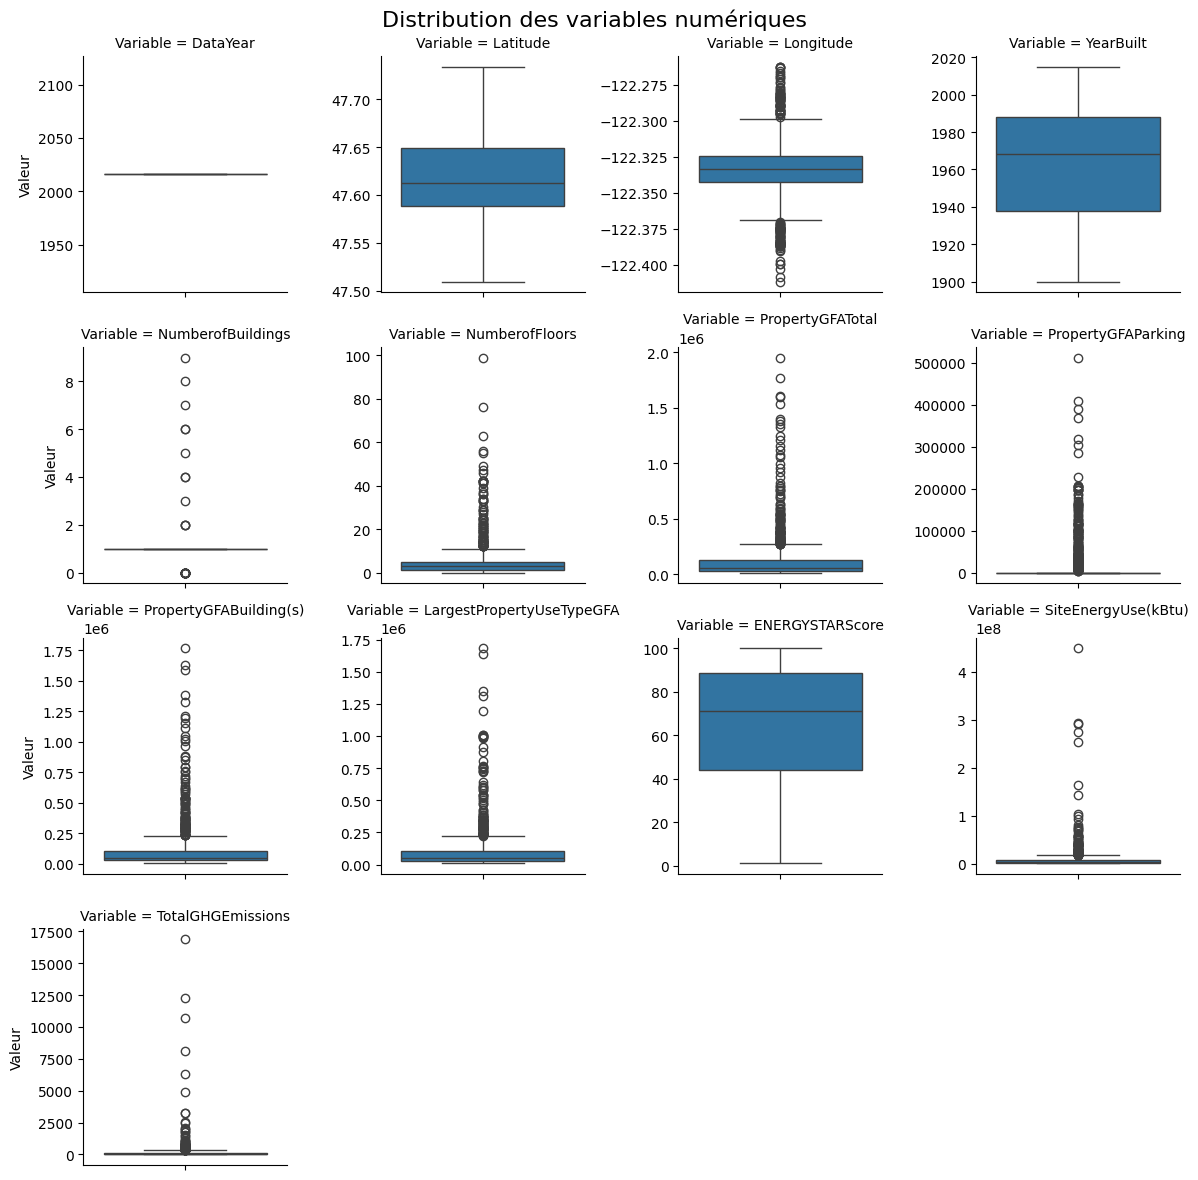

In [34]:
# Selection des variables que l'on souhaite visualiser dans les boxplots
Analysed_features = [col for col in Data_2.columns 
                  if Data_2[col].dtype in ['float64', 'int64'] and  col not in Features_to_remove]

# Appel de la fonction
dist_grid(Data_2, Analysed_features, sns.boxplot,4, "explicatives d'origine")


<Figure size 800x600 with 0 Axes>

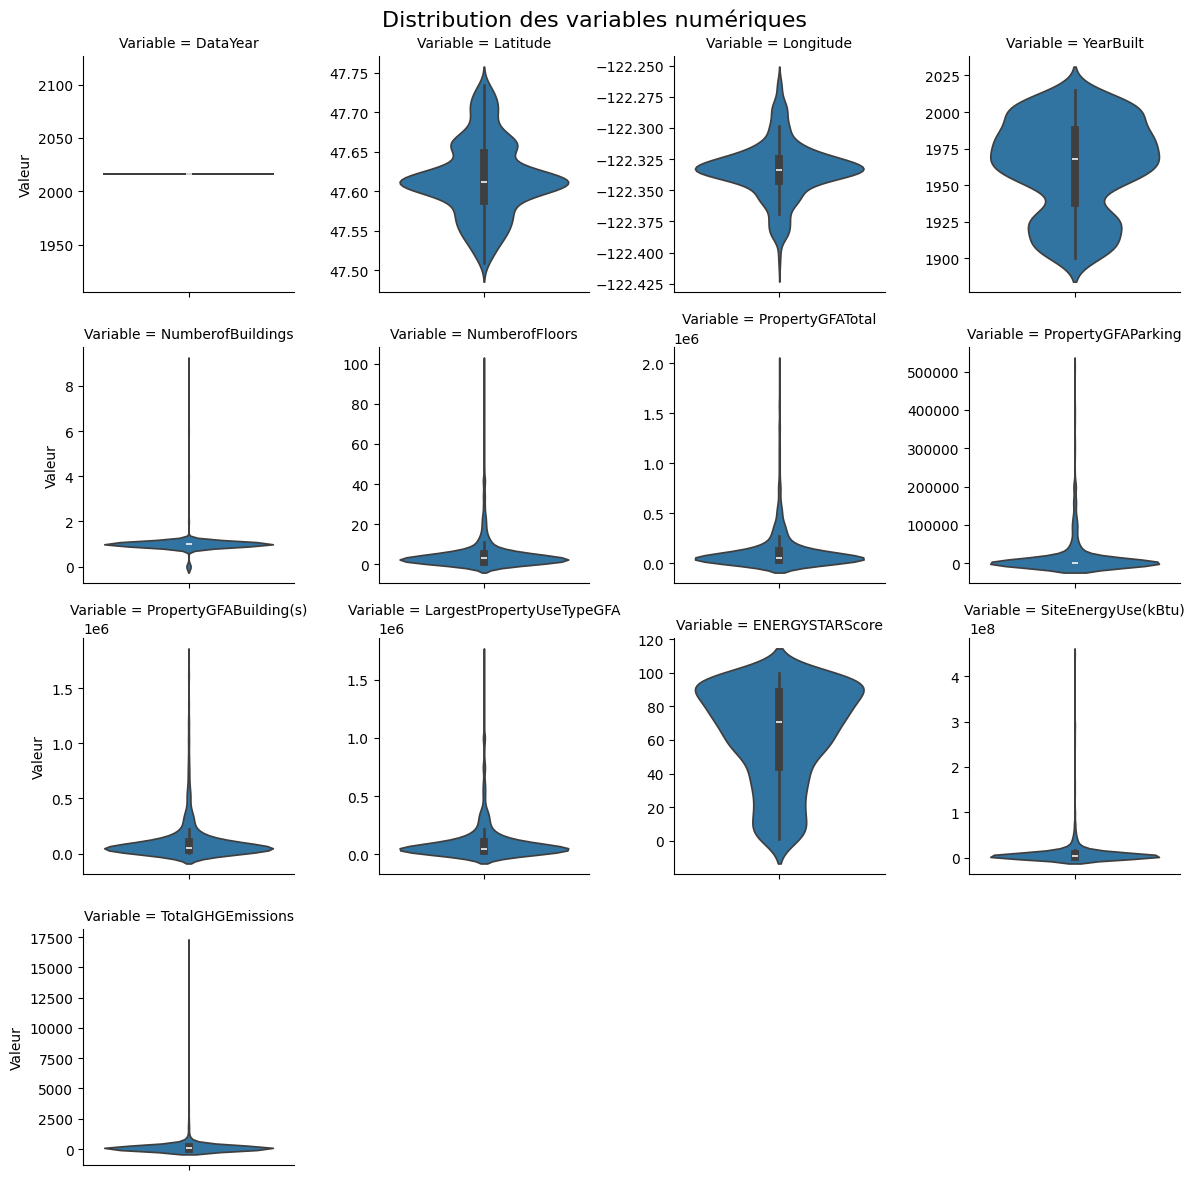

In [35]:
# Appel de la fonction
dist_grid(Data_2, Analysed_features, sns.violinplot, 4, "explicatives d'origine")

In [36]:
# Visulisation des différentes mesures descriptives des variables numériques
Data_2[Analysed_features].describe()

,DataYear,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
count,982.0,982.000000,982.000000,982.000000,982.000000,982.000000,9.820000e+02,982.000000,9.820000e+02,9.800000e+02,982.000000,9.820000e+02,982.000000
mean,2016.0,47.615984,-122.333774,1963.305499,1.022403,5.180244,1.309409e+05,16769.110998,1.141718e+05,1.073325e+05,63.703666,8.960416e+06,196.638758
std,0.0,0.047322,0.022742,31.933103,0.518277,8.214448,2.135708e+05,47992.334741,1.859495e+05,1.733973e+05,28.873388,2.600655e+07,868.094531
min,2016.0,47.509590,-122.411820,1900.000000,0.000000,0.000000,1.630000e+04,0.000000,3.636000e+03,8.061000e+03,1.000000,7.971180e+04,-0.800000
25%,2016.0,47.588012,-122.342838,1938.000000,1.000000,1.000000,3.178175e+04,0.000000,3.041550e+04,2.800000e+04,44.000000,1.269488e+06,20.292500
50%,2016.0,47.612345,-122.333540,1968.000000,1.000000,3.000000,5.392750e+04,0.000000,5.080850e+04,4.866450e+04,71.000000,2.829813e+06,49.675000
75%,2016.0,47.648610,-122.324687,1988.000000,1.000000,5.000000,1.275558e+05,0.000000,1.087700e+05,1.048822e+05,88.750000,7.794638e+06,144.695000
max,2016.0,47.733870,-122.262230,2015.000000,9.000000,99.000000,1.952220e+06,512608.000000,1.765970e+06,1.680937e+06,100.000000,4.483853e+08,16870.980000


**Description des résultats**

- **DataYear** : Les données ont uniquement été obtenues en 2016. Cette variable ne sera pas informative et ne sera pas inclue dans le model d'apprentissage

- **Latitute et Longitude** : Les valeurs de latitude et de longitude semblent bien s'inscrire dans un intervalle cohérent, en accord avec la situation géographique de Seattle.

- **YearBuilt** :  Cette variable ne contient pas d'outlier et ne semble pas contenir de valeurs aberrantes.

- **Numberoffloors** et **NumberofBuildings** : Il est étonnant d'observer 0 batiment ou 0 étage, il faudra analyser plus en détail et traiter ces valeurs.

- **GFA** : Les variables liées à la surface au sol présentent un nombre significatif d'outliers. Toutefois, ces anomalies pourraient être expliquées par le type des propriétés concernées, certaines propriétés plus rares pouvant atteindre des valeurs extrêmes. Une analyse de ces outliers permettront de mieux comprendre à quoi ces propriétés correspondent et si ces valeurs sont aberrantes ou juste plus rares.

- **ENERGYSTARscore** : La distribution de cette variable  est conforme à la définition de cette mesure, et s'inscrit dans un intervalle attendu.

La variable DataYear ne sera pas pris en compte lors de l'étape de modélisation

In [37]:
# Ajout des nouvelles variables à retirer dans la liste des variables à exclure
Features_to_remove =  Features_to_remove + ['DataYear']

**Analyse approfondie des outliers identifiés dans les variables liées aux sufraces**

In [38]:
# PropertyFGATotal
Data_2[['PrimaryPropertyType', 'PropertyName',
        'NumberofBuildings','NumberofFloors',
        'Address', 'PropertyGFATotal','PropertyGFAParking',
        'PropertyGFABuilding(s)', 'LargestPropertyUseType',
        'LargestPropertyUseTypeGFA']].sort_values('PropertyGFATotal', ascending=False).head(10)

,PrimaryPropertyType,PropertyName,NumberofBuildings,NumberofFloors,Address,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA
559,Large Office,Columbia Center - 2015,1.0,76,701 5th Avenue,1952220,319400,1632820,Office,1680937.0
618,Hospital,Swedish First Hill,7.0,14,747 Broadway,1765970,0,1765970,Hospital (General Medical & Surgical),1639334.0
292,Large Office,Two Union Square,1.0,56,601 Union St.,1605578,389860,1215718,Office,1314475.0
490,Large Office,Russell Investments Center,1.0,42,1301 2nd Ave,1592914,0,1592914,Office,914832.0
273,Large Office,US Bank Centre,1.0,46,1420 5th Avenue,1536606,512608,1023998,Office,1002403.0
271,Large Office,1201 Third Avenue,1.0,55,1201 3rd ave,1400000,285000,1115000,Office,994116.0
477,Large Office,Starbucks Center,0.0,6,2401 Utah Ave South,1380959,0,1380959,Office,1000730.0
233,Large Office,Seattle Municipal Tower (2030),1.0,63,700 Fifth Avenue,1354987,159600,1195387,Office,1191115.0
221,Large Office,999 Third Avenue,1.0,47,"999 3rd Avenue, Suite 1550",1323055,0,1323055,Office,1011135.0
577,Large Office,800 Fifth Avenue,1.0,42,800 5th Ave,1249055,201121,1047934,Office,983697.0


Les propriétés avec des surface très élevées correspondent soit à des propriétés avec un grand nombre d'étage, soit à un hopital. 
On note aussi une surface extrême pour le Starbuck Center qui n'a que 6 étages. Sa visualisation sur google map semble indiquer une surface par étage importante. Ces valeurs  de surface bien qu'élevées ne paraissent pas anormales au vu des caractéristiques de ces propriétés.

In [39]:
# PropertyFGAParking
Data_2[['PrimaryPropertyType', 'PropertyName',
        'NumberofBuildings','NumberofFloors',
        'Address', 'PropertyGFATotal','PropertyGFAParking',
        'PropertyGFABuilding(s)', 'LargestPropertyUseType',
        'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType']].sort_values('PropertyGFAParking', ascending=False).head(10)

,PrimaryPropertyType,PropertyName,NumberofBuildings,NumberofFloors,Address,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType
273,Large Office,US Bank Centre,1.0,46,1420 5th Avenue,1536606,512608,1023998,Office,1002403.0,Parking
307,Medical Office,1101 Madison Tower,1.0,14,1101 Madison,690158,407795,282363,Medical Office,270384.0,Parking
292,Large Office,Two Union Square,1.0,56,601 Union St.,1605578,389860,1215718,Office,1314475.0,Parking
229,Large Office,Safeco Plaza,1.0,49,1001 Fourth Avenue,1123435,368980,754455,Office,808980.0,Parking
559,Large Office,Columbia Center - 2015,1.0,76,701 5th Avenue,1952220,319400,1632820,Office,1680937.0,Parking
77,Large Office,Bill and Melinda Gates Foundation,1.0,6,500 5th Ave N,920598,303707,616891,Office,729584.0,Parking
271,Large Office,1201 Third Avenue,1.0,55,1201 3rd ave,1400000,285000,1115000,Office,994116.0,Parking
212,Large Office,West 8th,1.0,25,2001 - 8th Avenue,758043,228668,529375,Office,582725.0,Parking
338,Large Office,Arnold Building,1.0,5,1100 Fairview Ave No.,560516,206597,353919,Office,372503.0,Parking
492,Medical Office,Elmer J. Nordstrom Medical Tower,1.0,10,1229 madison Street,422503,206580,215923,Medical Office,197408.0,NaN


On remarque que pour chacune de ces propriétés le parking correspond a la deuxième plus forte utilisation associés à la propriété. Ce sont majoritairement des propriétés avec un grand nombre d'étage ce qui semblent indiquer une grand nombre de personne travaillant dans la propriété, et donc un potentiel nombre élevé de voiture à garer. 

In [40]:
# PropertyFGABuildings
Data_2[['PrimaryPropertyType', 'PropertyName',
        'NumberofBuildings','NumberofFloors',
        'Address', 'PropertyGFATotal','PropertyGFAParking',
        'PropertyGFABuilding(s)', 'LargestPropertyUseType',
        'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType']].sort_values('PropertyGFABuilding(s)', ascending=False).head(10)

,PrimaryPropertyType,PropertyName,NumberofBuildings,NumberofFloors,Address,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType
618,Hospital,Swedish First Hill,7.0,14,747 Broadway,1765970,0,1765970,Hospital (General Medical & Surgical),1639334.0,Parking
559,Large Office,Columbia Center - 2015,1.0,76,701 5th Avenue,1952220,319400,1632820,Office,1680937.0,Parking
490,Large Office,Russell Investments Center,1.0,42,1301 2nd Ave,1592914,0,1592914,Office,914832.0,Parking
477,Large Office,Starbucks Center,0.0,6,2401 Utah Ave South,1380959,0,1380959,Office,1000730.0,Retail Store
221,Large Office,999 Third Avenue,1.0,47,"999 3rd Avenue, Suite 1550",1323055,0,1323055,Office,1011135.0,Parking
292,Large Office,Two Union Square,1.0,56,601 Union St.,1605578,389860,1215718,Office,1314475.0,Parking
233,Large Office,Seattle Municipal Tower (2030),1.0,63,700 Fifth Avenue,1354987,159600,1195387,Office,1191115.0,Parking
170,Hospital,Harborview Medical Center,9.0,8,325 9th Ave.,1158691,0,1158691,Hospital (General Medical & Surgical),1350182.0,Parking
271,Large Office,1201 Third Avenue,1.0,55,1201 3rd ave,1400000,285000,1115000,Office,994116.0,Parking
577,Large Office,800 Fifth Avenue,1.0,42,800 5th Ave,1249055,201121,1047934,Office,983697.0,Parking


Les propriétés dont la surface attribuée au bâtiment est la plus élevée correspondent à peu pres aux même que celles identifiées comme ayant une surface globale élevée. Les mêmes conclusions peuvent être faites pour les outliers identifiés pour cette variable.

In [41]:
# LargestPropertyUseTypeGFA
Data_2[['PrimaryPropertyType', 'PropertyName',
        'NumberofBuildings','NumberofFloors',
        'Address', 'PropertyGFATotal','PropertyGFAParking',
        'PropertyGFABuilding(s)', 'LargestPropertyUseType',
        'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType']].sort_values('LargestPropertyUseTypeGFA', ascending=False).head(10)

,PrimaryPropertyType,PropertyName,NumberofBuildings,NumberofFloors,Address,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType
559,Large Office,Columbia Center - 2015,1.0,76,701 5th Avenue,1952220,319400,1632820,Office,1680937.0,Parking
618,Hospital,Swedish First Hill,7.0,14,747 Broadway,1765970,0,1765970,Hospital (General Medical & Surgical),1639334.0,Parking
170,Hospital,Harborview Medical Center,9.0,8,325 9th Ave.,1158691,0,1158691,Hospital (General Medical & Surgical),1350182.0,Parking
292,Large Office,Two Union Square,1.0,56,601 Union St.,1605578,389860,1215718,Office,1314475.0,Parking
233,Large Office,Seattle Municipal Tower (2030),1.0,63,700 Fifth Avenue,1354987,159600,1195387,Office,1191115.0,Parking
221,Large Office,999 Third Avenue,1.0,47,"999 3rd Avenue, Suite 1550",1323055,0,1323055,Office,1011135.0,Parking
3264,Hospital,Virginia Mason Medical Center - 2149,1.0,8,925 Seneca St.,374466,0,374466,Hospital (General Medical & Surgical),1010135.0,NaN
273,Large Office,US Bank Centre,1.0,46,1420 5th Avenue,1536606,512608,1023998,Office,1002403.0,Parking
477,Large Office,Starbucks Center,0.0,6,2401 Utah Ave South,1380959,0,1380959,Office,1000730.0,Retail Store
49,Hotel,Sheraton Seattle Hotel,1.0,34,1400 6th Avenue,994212,146694,847518,Hotel,994212.0,Parking


A nouveau, les propriétés dont la surface attribuée a la plus forte utilisation de la propriété est la plus élevée correspondent à peu pres aux même que celles identifiées comme ayant une surface globale élevée. Les mêmes conclusions peuvent être faites pour les outliers identifiés pour cette variable.

**Analyse approfondies des outliers identifiés pour le nombre de bâtiments et d'étages**   

Les variables concernant le nombre de bâtiments et le nombre d'étage prenne un nombre limité de valeur. On peut donc analyser un peu plus finement leur distribution en les représentant avec un countplot.

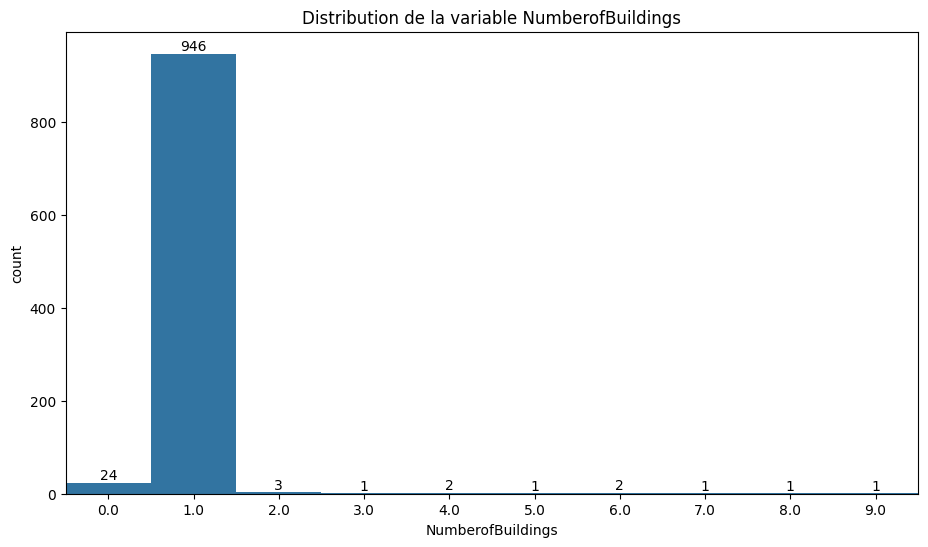

In [42]:
# Analyse de la distribution de la variable NumberofBuildings
Selected_Features = 'NumberofBuildings'
countplot_var(Data_2, Selected_Features, figsize=(11, 6))

On remarque que la majorité des observations n'ont qu'un bâtiment. Si on veut garder cette variable il pourrait être utile de la transformer. Plusieurs options sont envisageables. L'une d'entre elles consiste à créer une variable binaire indiquant si une propriété possède un ou plus d'un bâtiment.

De plus, il est étonnant d'avoir 24 observations avec 0 bâtiment. Les valeurs 0 dans la variables nombre de bâtiments seront remplacées par la classe majoritaire -> 1.

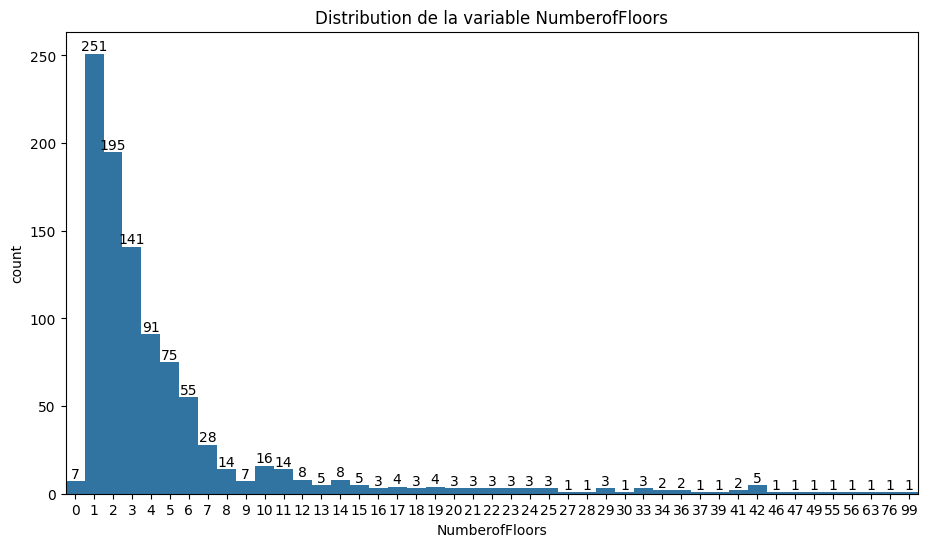

In [43]:
# Analyse de la distribution de la variable Numberoffloors
Selected_Features = 'NumberofFloors'
countplot_var(Data_2, Selected_Features, figsize=(11, 6))

Il est également étonnant d'avoir 6 observations avec 0 étâge. De même il serait judicieux de vérifier les bâtiments avec plus de 60 étages afin de s'assurer que ces bâtiments avec un nombre d'étage très élevé et peu commun ont bien un nombre d'étage cohérent. On peut regarder plus en détails à quoi ces observations correspondent.

In [44]:
# Analyse plus approfondie des bâtiments avec 0 ou plus de 60 étages
Data_2[(Data_2['NumberofFloors']>60) |  (Data_2['NumberofFloors']==0) ][
    ['OSEBuildingID','NumberofFloors','PrimaryPropertyType', 'PropertyName', 'Address', 
    'PropertyGFATotal', 'PropertyGFAParking', 'LargestPropertyUseType']]

,OSEBuildingID,NumberofFloors,PrimaryPropertyType,PropertyName,Address,PropertyGFATotal,PropertyGFAParking,LargestPropertyUseType
233,357,63,Large Office,Seattle Municipal Tower (2030),700 Fifth Avenue,1354987,159600,Office
487,656,0,Medical Office,Arnold Pavilion,1221 Madison Street,225982,0,Medical Office
488,657,0,Mixed Use Property,2200 Westlake - SEDO,2200 Westlake Ave.,516407,0,Parking
559,775,76,Large Office,Columbia Center - 2015,701 5th Avenue,1952220,319400,Office
1359,21611,99,Worship Facility,Seattle Chinese Baptist Church,5801 Beacon Avenue South,21948,0,Worship Facility
1754,23311,0,Medical Office,HART First Hill LLC,1124 Columbia Street,274568,0,Medical Office
3130,40028,0,Warehouse,Sandpoint #5,7561 63rd Ave NE,384772,0,Non-Refrigerated Warehouse
3131,40031,0,Medical Office,Sandpoint #25,6222 NE 74th St,30287,0,Medical Office
3132,40034,0,Small- and Mid-Sized Office,Sandpoint #29,6200 NE 74th ST,21931,0,Office
3276,49970,0,Residence Hall,Cedar Hall,1112 NE 41st ST,176225,0,Residence Hall/Dormitory


En recherchant ces bâtiments sur google map, on s'aperçoit que
- les bâtiments notés avec 0 étage ont 1 voir plus d'étages. Ces propriétés étant présentes en faible proportion nous les éliminerons du jeu de données pour éviter d'introduire des biais liés au nombre d'étage.
- les bâtiments avec plus de 60 étages semblent bien être des bâtiments très haut mis à part pour l'église qui ne contient qu'un étage et que nous allons corriger -> ID : 21611

### Représentation graphique et analyse des variables prédictives qualitatives

**Localisation**

Plusieurs variables renseignent sur la région géographique des propriétés.
- Le code postal (ZipCode)
- Le quartier (Neighborood)
- Concile distric Code
- La longitude et la latitude

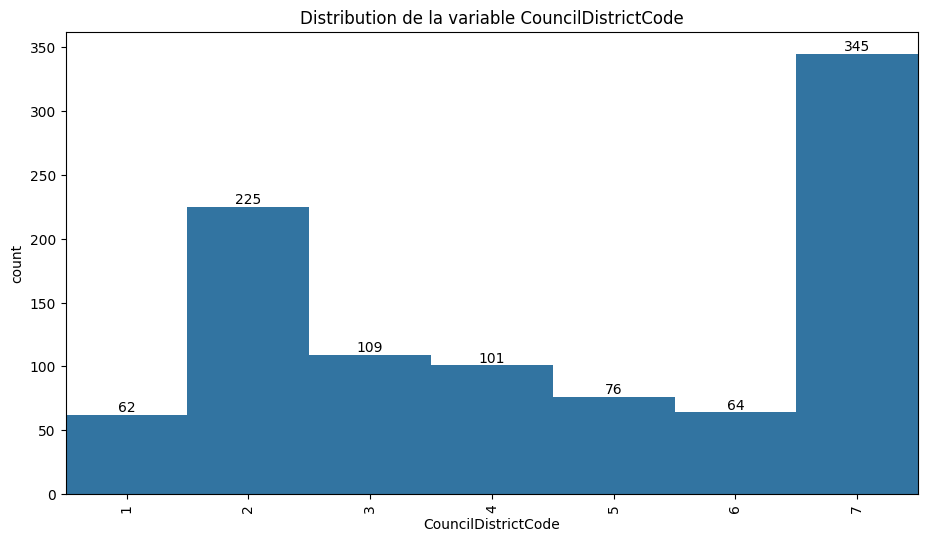

In [45]:
# Analyse de la distribution de la variable CouncilDistrictCode
countplot_var(Data_2, 'CouncilDistrictCode', figsize=(11, 6), label_rotated=True)

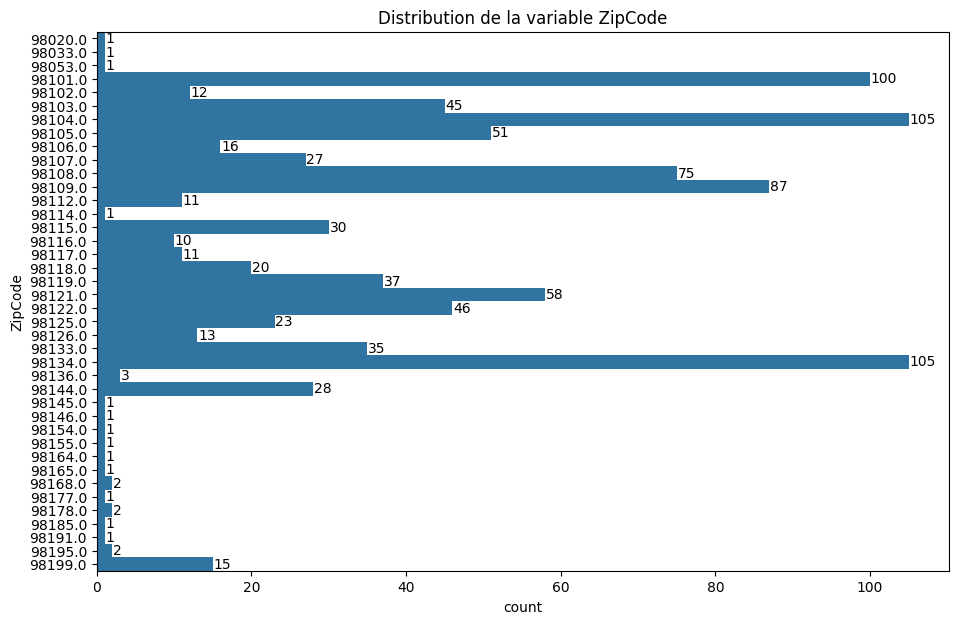

In [46]:
# Analyse de la distribution de la variable ZipCode
countplot_var(Data_2, 'ZipCode', False, orientation='horizontal', figsize=(11, 7))

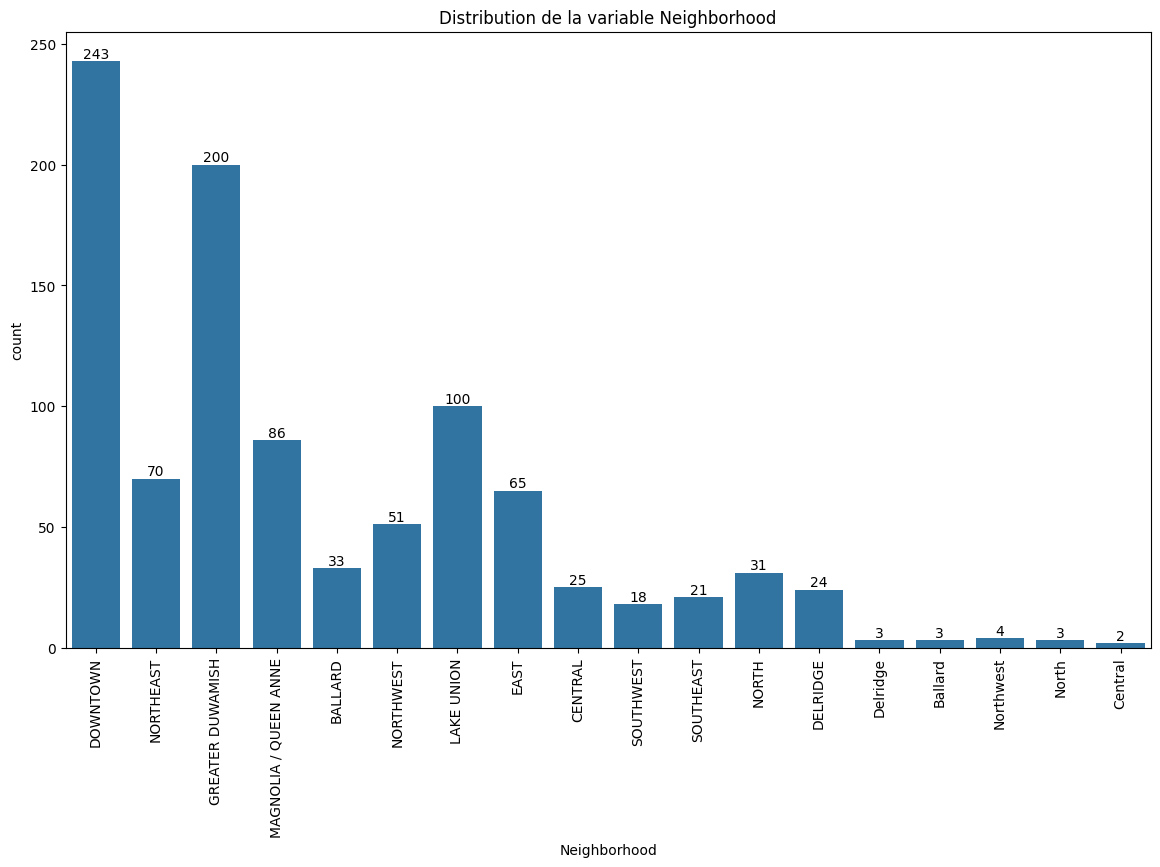

In [47]:
# Analyse de la distribution de la variable Neighborhood
countplot_var(Data_2, 'Neighborhood', False, bar_width=0.8, orientation='vertical', figsize=(14, 8), label_rotated = True)

Plusieurs observations peuvent être faites suite à l'analyse de ces trois variables
- La variable ZipCode contient beaucoup de catégories à faible effectif
- La variable Neighborhood contient des catégories redondantes qu'il faudra homogénéiser

La variable ZipCode ne sera pas utilisée pour l'étape de modélisation. Le choix entre la variable Neighborhood et CouciDistrictCode sera fait après plus d'analyse.

In [48]:
# Ajout des nouvelles variables à retirer dans la liste des variables à exclure
Features_to_remove = Features_to_remove +['ZipCode']

**Type d'utilisation**

Plusieurs variables sont liées au type de la propriété
- BuildingType
- PrimaryPropertyType
- LargestPropertyUseType

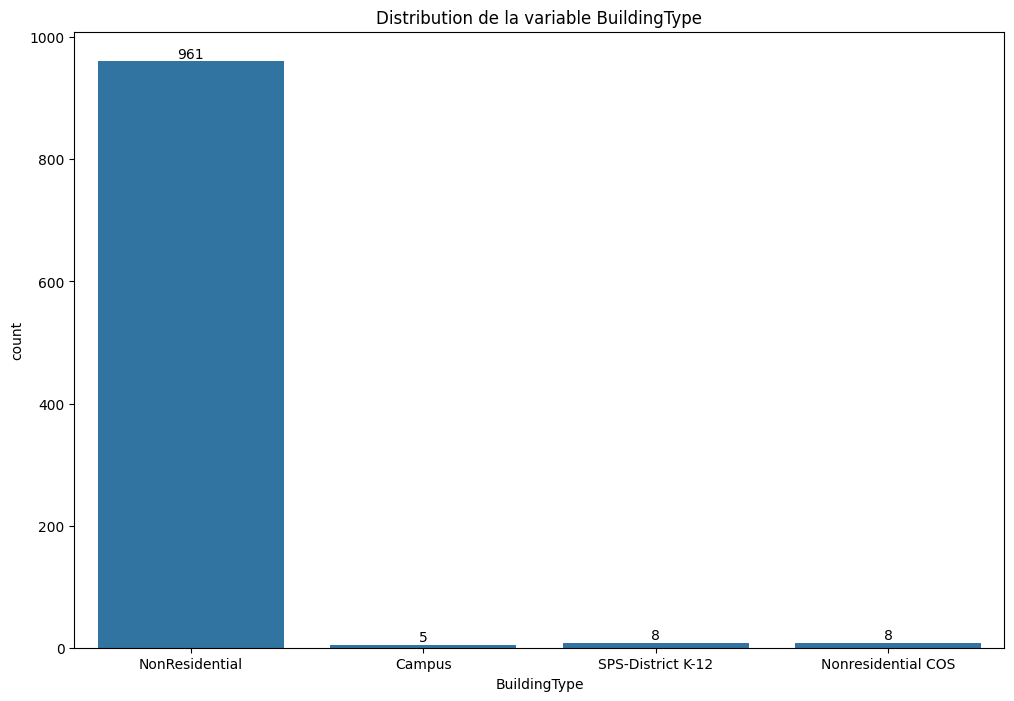

In [49]:
# Analyse de la distribution de la variable BuildingType
countplot_var(Data_2, 'BuildingType', False, bar_width=0.8, orientation='vertical', figsize=(12, 8))

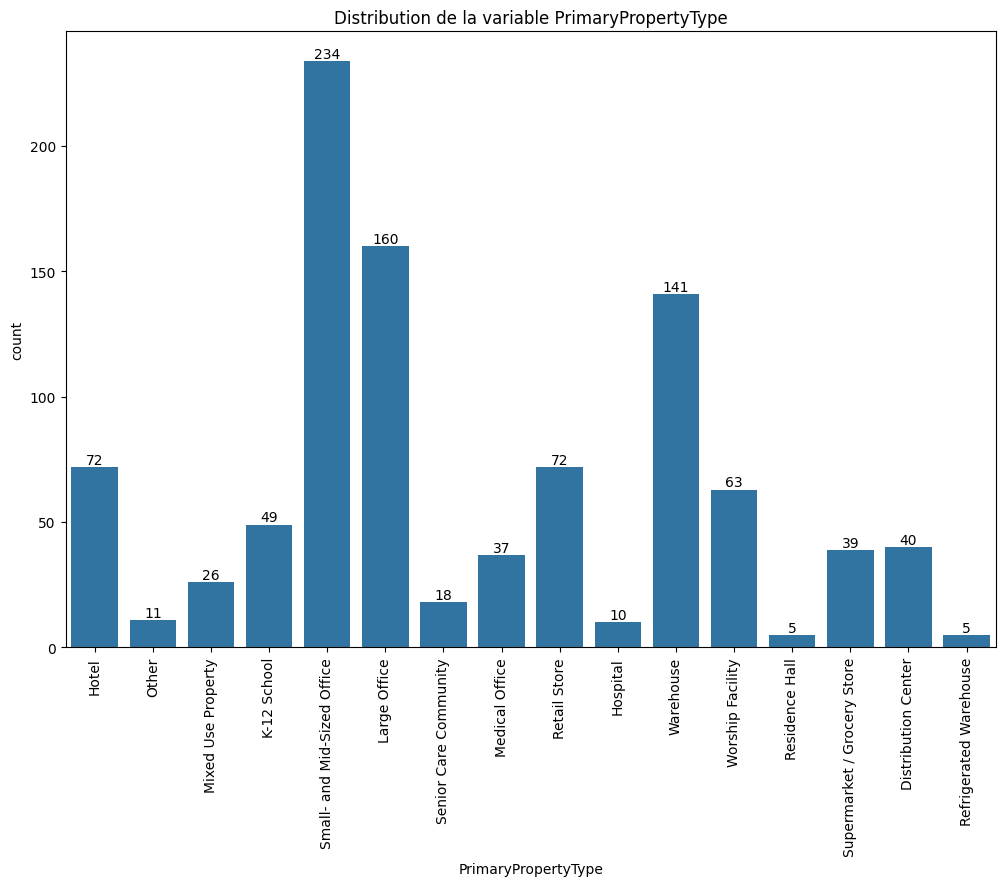

In [50]:
# Analyse de la distribution de la variable PrimaryPropertyType
countplot_var(Data_2, 'PrimaryPropertyType', True, bar_width=0.8, orientation='vertical', figsize=(12, 8), label_rotated = True)

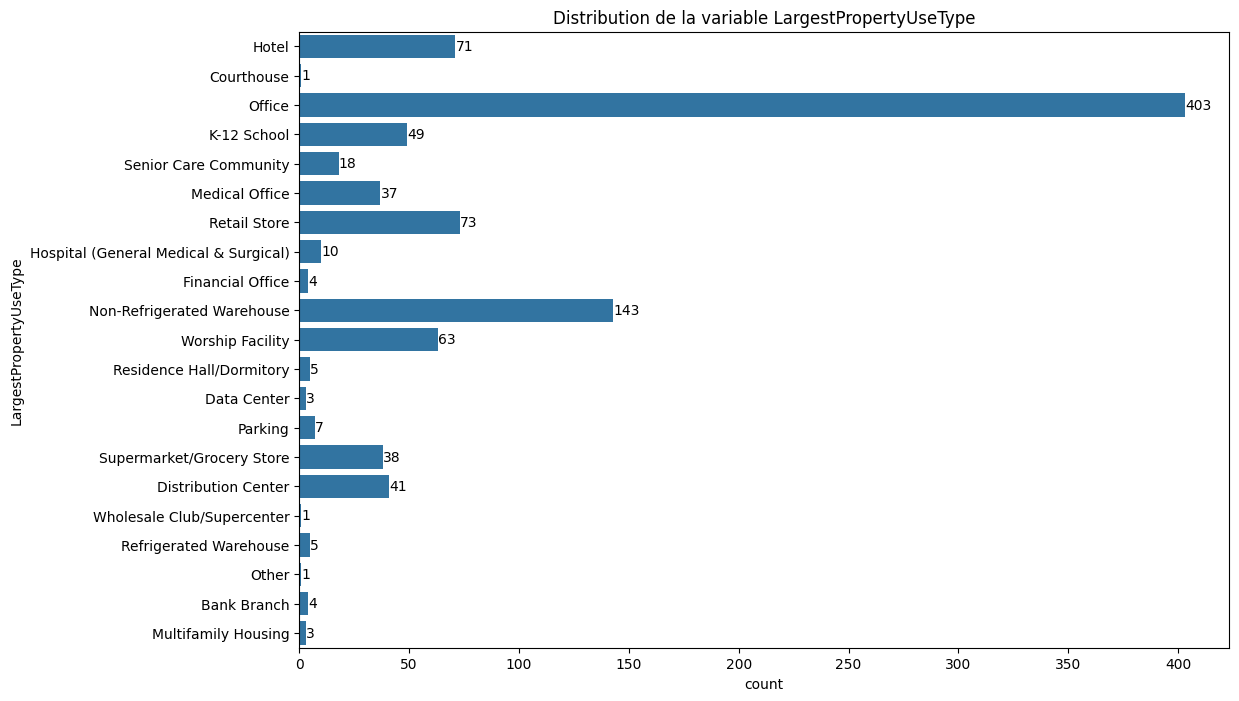

In [51]:
# Analyse de la distribution de la variable LargestPropertyUseType
countplot_var(Data_2, 'LargestPropertyUseType', False, bar_width=0.8, orientation='horizontal', figsize=(12, 8))

Plusieurs observations peuvent être faites:
- La variable  BuildingType varie peu, l'essentiel des type de propriété sont dans NonResidential
- La variable LargestPropertyUseType contient beaucoup de catégorie à faible effectif. 

La variable qui semble le plus facilement utilisable dans l'étape de modélisation est la variable PrimaryPropertyType

In [52]:
# Ajout des nouvelles variables à retirer dans la liste des variables à exclure
Features_to_remove = Features_to_remove + ['BuildingType', 'LargestPropertyUseType']

### Représentation des variables liées à l'énergie

On peut également analyser les variables cibles ainsi que certaines variables liées aux variables cibles.

<Figure size 800x600 with 0 Axes>

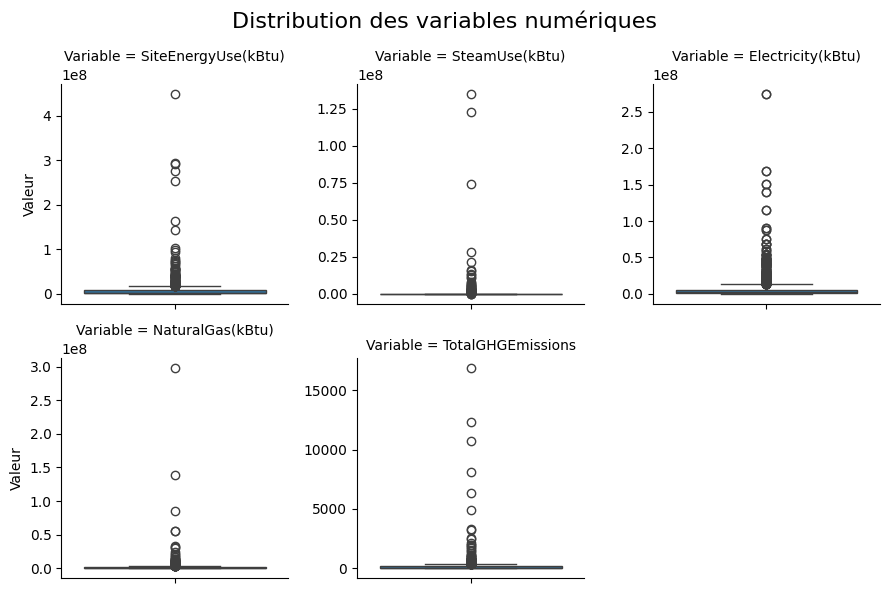

In [53]:
# Selection des variables que l'on souhaite visualiser dans les graphiques
Analysed_features=['SiteEnergyUse(kBtu)', 'SteamUse(kBtu)', 'Electricity(kBtu)', 'Electricity(kBtu)',
                   'NaturalGas(kBtu)', 'TotalGHGEmissions']

# Apppel de la fonction
dist_grid(Data_2, Analysed_features, sns.boxplot,3, "variables énergétiques")

<Figure size 800x600 with 0 Axes>

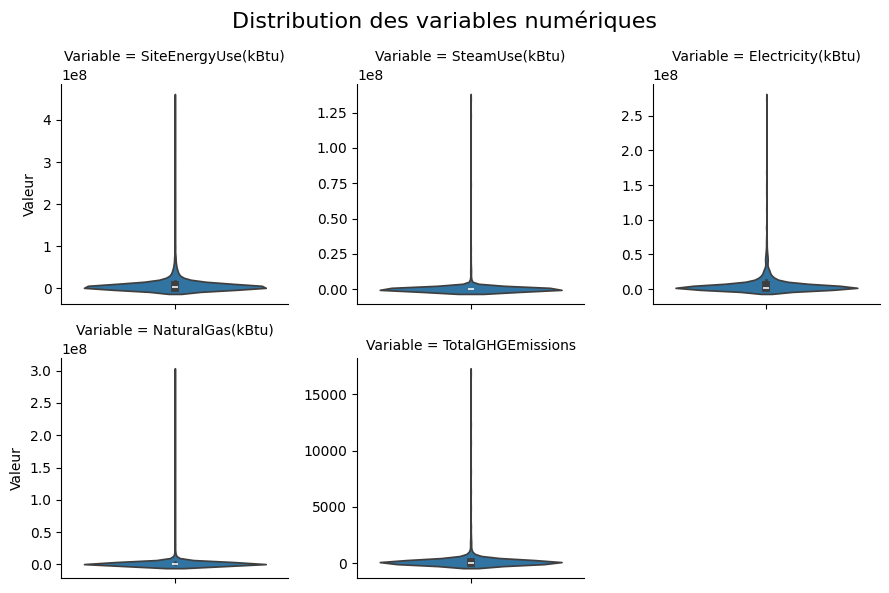

In [54]:
# Affichage des distribution des variables numériques
dist_grid(Data_2, Analysed_features, sns.violinplot, 3, "variables énergétiques")

In [55]:
# Description des données numériques
Data_2[Analysed_features].describe()

,SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions
count,9.820000e+02,9.820000e+02,9.820000e+02,9.820000e+02,9.820000e+02,982.000000
mean,8.960416e+06,6.059642e+05,6.331364e+06,6.331364e+06,1.990722e+06,196.638758
std,2.600655e+07,6.482134e+06,1.582558e+07,1.582558e+07,1.138956e+07,868.094531
min,7.971180e+04,0.000000e+00,-1.154170e+05,-1.154170e+05,0.000000e+00,-0.800000
25%,1.269488e+06,0.000000e+00,8.001288e+05,8.001288e+05,0.000000e+00,20.292500
50%,2.829813e+06,0.000000e+00,1.889543e+06,1.889543e+06,3.960165e+05,49.675000
75%,7.794638e+06,0.000000e+00,5.662098e+06,5.662098e+06,1.393594e+06,144.695000
max,4.483853e+08,1.349435e+08,2.745325e+08,2.745325e+08,2.979090e+08,16870.980000


Les variables liées aux dépenses énergétiques présentent des valeurs exrèmes. Toutefois, ces anomalies pourraient être expliquées par le type de la propriété concernée, certaines propriétés plus rares pouvant atteindre des valeurs extrêmes. On va analyser de façon plus approfondie les différentes caractéristiques de ces prorpiétés. 

**Valeur les plus faibles**

In [56]:
# Affichage des propriétés ayant une forte valeur en consommation énergétique
Data_2[['OSEBuildingID', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 
        'Address', 'PropertyName', 'Electricity(kBtu)', 'SiteEnergyUse(kBtu)',
        'TotalGHGEmissions', 'Outlier']].sort_values('Electricity(kBtu)').head(5)

,OSEBuildingID,LargestPropertyUseType,LargestPropertyUseTypeGFA,Address,PropertyName,Electricity(kBtu),SiteEnergyUse(kBtu),TotalGHGEmissions,Outlier
3206,49784,Office,48159.0,1501 E. Madison St.,Bullitt Center,-115417.0,3.427261e+05,-0.80,NaN
513,700,Supermarket/Grocery Store,39500.0,2001 15th Avenue West,IUC- Whole Foods Interbay,0.0,1.252517e+07,0.00,NaN
174,281,K-12 School,55500.0,5031 University Way NE,University HTS Grade School,6138.0,1.377627e+06,72.88,NaN
265,392,Non-Refrigerated Warehouse,51116.0,910 N 137th St,Linden Bldg,16765.0,9.306119e+05,48.65,NaN
1766,23342,Non-Refrigerated Warehouse,21936.0,12547 26th AVE NE,Daily Racing Form,71827.0,1.131300e+05,2.69,NaN


Une seule propriété à une consommation en éléctricité négative. Celle ci est attribuée à un centre commercial réputé comme étant le centre commercial le plus écologique du monde. Parmis les différents atouts de cette propriété figure l'utilisation de panneaux solaire. Les valeurs de cette propriété ne sont donc pas anormale compte tenu de ses caractéristiques. Cependant cette valeur négative étant obtenue pour une seule prorpiété, celle-ci sera exclue de l'analyse. -> ID: 49784

**Valeur les plus élevées**

In [57]:
# Affichage des propriétés ayant une faible valeurs en consommation énergétique
Data_2[['OSEBuildingID', 'PrimaryPropertyType', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 
        'Address', 'PropertyName', 'Electricity(kBtu)', 'SiteEnergyUse(kBtu)',
        'TotalGHGEmissions', 'Outlier']].sort_values('SiteEnergyUse(kBtu)', ascending=False).head(10)

,OSEBuildingID,PrimaryPropertyType,LargestPropertyUseType,LargestPropertyUseTypeGFA,Address,PropertyName,Electricity(kBtu),SiteEnergyUse(kBtu),TotalGHGEmissions,Outlier
35,43,Mixed Use Property,Office,757027.0,7755 E MARGINAL WAY S,Plant 2 Site,150476283.0,448385312.0,16870.98,NaN
170,276,Hospital,Hospital (General Medical & Surgical),1350182.0,325 9th Ave.,Harborview Medical Center,168683602.0,293090784.0,10734.57,NaN
618,828,Hospital,Hospital (General Medical & Surgical),1639334.0,747 Broadway,Swedish First Hill,139354828.0,291614432.0,12307.16,NaN
558,753,Other,Data Center,218997.0,2001 6th Ave,WestinBuilding,274532495.0,274682208.0,1921.82,NaN
124,198,Hospital,Hospital (General Medical & Surgical),879000.0,4800 Sand Point Way NE,Seattle Children's Hospital Main Campus,115641210.0,253832464.0,8145.52,NaN
3264,49940,Hospital,Hospital (General Medical & Surgical),1010135.0,925 Seneca St.,Virginia Mason Medical Center - 2149,90060497.0,163945984.0,6330.91,NaN
167,268,Hospital,Hospital (General Medical & Surgical),601615.0,500 17th Ave,Swedish Cherry Hill,58754927.0,143423024.0,4906.33,NaN
1690,23113,Medical Office,Medical Office,520187.0,201 16th Ave. E.,Central Campus,48002292.0,102673696.0,3238.24,NaN
1672,23071,Hospital,Hospital (General Medical & Surgical),483520.0,Facilities Management MS: B-120,Main Hospital - All Wings,42864158.0,98960776.0,3278.11,NaN
559,775,Large Office,Office,1680937.0,701 5th Avenue,Columbia Center - 2015,87851862.0,92937640.0,882.56,NaN


La consommation d'énergie la plus élevée du jeu de données est attribuée au site Plant 2, une usine aérospatiale. Bien que ces valeurs de consommation énergétique puissent sembler extrêmes, elles sont cohérentes avec l'activité industrielle du site. Toutefois, ce cas très particulier risque de biaiser l'apprentissage du modèle. En effet, il est peu probable qu'une seconde usine aérospatiale s'installe prochainement à Seattle, ce qui rend cet exemple peu représentatif du reste des données. Les 4 autres propriétés avec une consommation en électricité particulièrement élevée correspondent à des Hopitaux ou Datacenter connus pour être de gros consommateur d'éléctricité et seront donc conservées. 

### Deuxième nettoyage des données 

Au cours de l'analyse exploratoire nous avons vu différents point de nettoyage à réaliser
- nombre de bâtiments et d'étages : traiter les valeurs à 0 et corriger le nombre d'étage de l'église qui avait 99 étages
- quartier : homogénéiser les catégories
- deux propriétés à retirer car données trop extrèmes

In [58]:
# Copie de la dataframe
Data_3 = Data_2.copy()

#### Nettoyage de la variable Neighborhood

Lors de l'analyse univariée nous avons remarqué la présence de certaines catégories redondantes dans la variable 'Neighborhood'. Ces catégories redondantes étaient toutes liées à une Typographique différentes certaines étant écrite en majuscules et d'autre en minuscule. Les catégories de cette variable seront donc homogénéisées en transformant toutes les valeurs de la variable en chaines de caractères écrite en minuscule avec le premier caractère en majuscule.

In [59]:
# Transformations des valeurs de la variable Neighborhood
Data_3.loc[:, 'Neighborhood'] = Data_3['Neighborhood'].str.capitalize()

# Visualisation des différentes catégories pour s'assurer qu'il n'y a plus de catégories redondantes
Data_3['Neighborhood'].value_counts()

Neighborhood
Downtown                 243
Greater duwamish         200
Lake union               100
Magnolia / queen anne     86
Northeast                 70
East                      65
Northwest                 55
Ballard                   36
North                     34
Central                   27
Delridge                  27
Southeast                 21
Southwest                 18
Name: count, dtype: int64

#### Nettoyage des variables liées au nombre d'étage et de bâtiment

Lors de l'analyse univariée nous avons remarqué que certaines propriétés possédaient 0 bâtiment. Il a été choisi de remplacer ces valeurs anormales par la valeur la plus fréquente à savoir 1.
De plus, une valeur anormale de nombre d'étage a été détectée pour une église qui ne contient en réalité qu'un égage. La valeur de cette propriété va dont être corrigée.

In [60]:
# Traitement des valeurs anormales pour la variable NumberofBuildings
Data_3.loc[Data_3['NumberofBuildings'] == 0, 'NumberofBuildings'] = 1

# Correction de la valeur anormale détectée pour l'église
Data_3.loc[Data_3['OSEBuildingID'] == 21611 , 'NumberofFloors'] = 1

#### Filtres

Lors de l'analyse univariée, nous avons remarqué que 6 propriétés possédaient 0 étage. Après vérification sur google map, il a été constaté que ces bâtiments possédaient en réalité un nombre variable d'étage. Afin d'éviter d'introduire des biais dans le modèle, il a été choisi de retirer ces bâtiments.

In [61]:
# Filtre des bâtiments avec 0 étage
Data_3 = Data_3[(Data_3['NumberofFloors'] != 0)]

Par ailleurs, il a également été discuté de supprimer les propriété dont la consommation en énergie était extrème et trop rarement atteinte dans le jeu de données. 

In [62]:
# Filtre des propriétés avec des valeurs trop extrème et rares
Data_3 = Data_3[(Data_3['OSEBuildingID']!=43) & (Data_3['OSEBuildingID']!=49784)]

## Analyses bi et multivariées

In [63]:
def boxplot_group_var_pred(df, features, group):
    
    """
    Affiche un boxplot d'une variable numérique en fonction d'un groupe catégoriel.

    La distribution de la variable numérique est représentée pour chaque modalité
    de la variable de groupement, permettant de comparer visuellement les différences
    de dispersion, de médiane et de valeurs extrêmes entre groupes.

    Paramètres
     - df (pandas.DataFrame): DataFrame contenant les données à visualiser.
     - features (str): Nom de la variable numérique à représenter sur l'axe des abscisses.
     - group (str): Nom de la variable catégorielle utilisée pour regrouper les observations
    """

    # Initialisation de la figure
    plt.figure(figsize=(12, 10))
    
    # Création du boxplot groupé
    sns.boxplot(y=group, x=features, data=df, hue=group)
    plt.title(f'Distribution des valeurs de {features} en fonction des groupes de {group}')
    plt.legend([], [], frameon=False)
    plt.savefig(f'../Output/Analyses exploratoires/Analyses bivariées/Distribution des valeurs de {features} en fonction des groupes de {group}.png', format='png')
    plt.show()

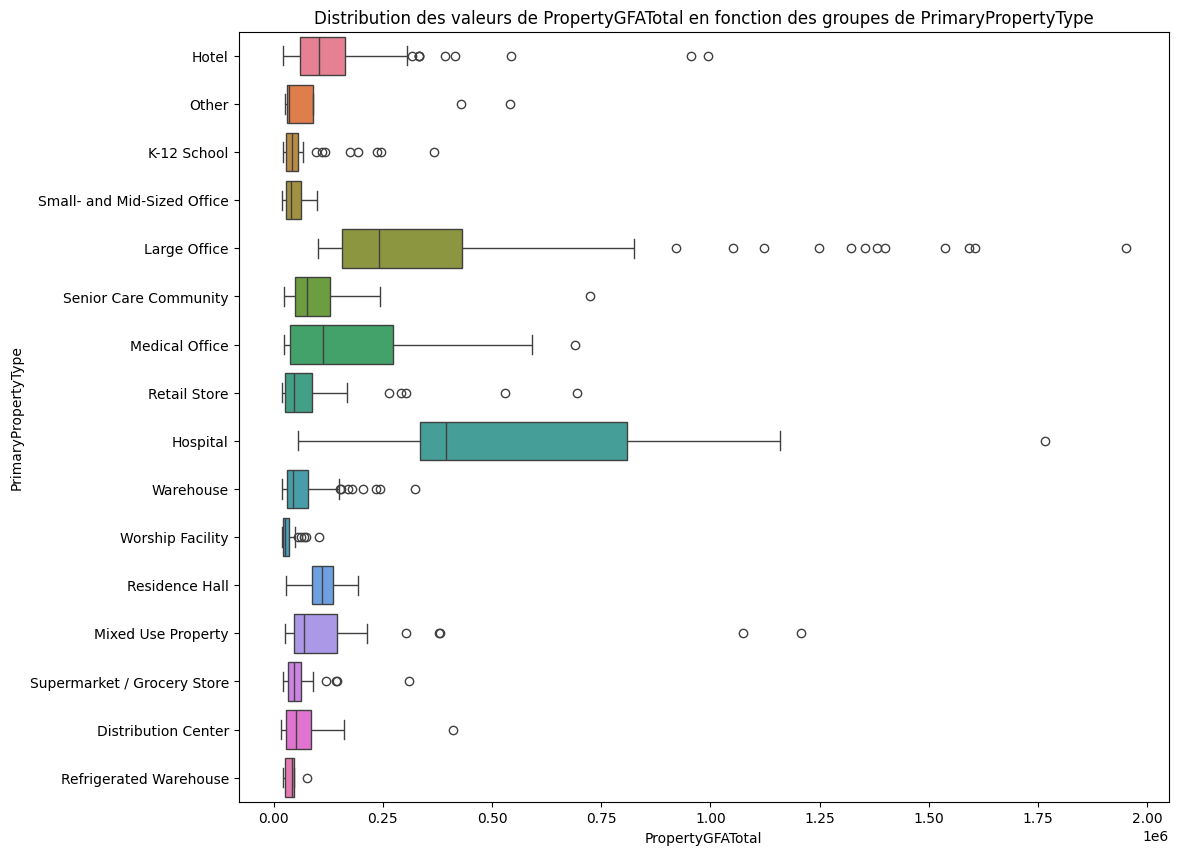

In [64]:
# Définition des variables a analyser
Selected_features='PropertyGFATotal'
groupe = 'PrimaryPropertyType'

# Affichage du graphique
boxplot_group_var_pred(Data_3, Selected_features, groupe)

Ce graphique permet de montrer que les surfaces des propriétés varient selon le type de la propriété. On remarque notamment que les lieux de culte et que les écoles ont des surfaces plus basses que les propriétés avec de grandes zones de bureaux. L'intéraction entre ces deux variables pourrait s'avérer utile pour les modèles en capturant des effets combinés qu'aucune des deux variables ne permettrait de modéliser seule.

Il pourrait également être intéressant de visualiser les différentes catégories de localisation en fonction de la Latitude et de la Longitude. Cette représentation peut montrer si l'une des deux variables localisant les popriétés retenues a une meilleure cohérence.

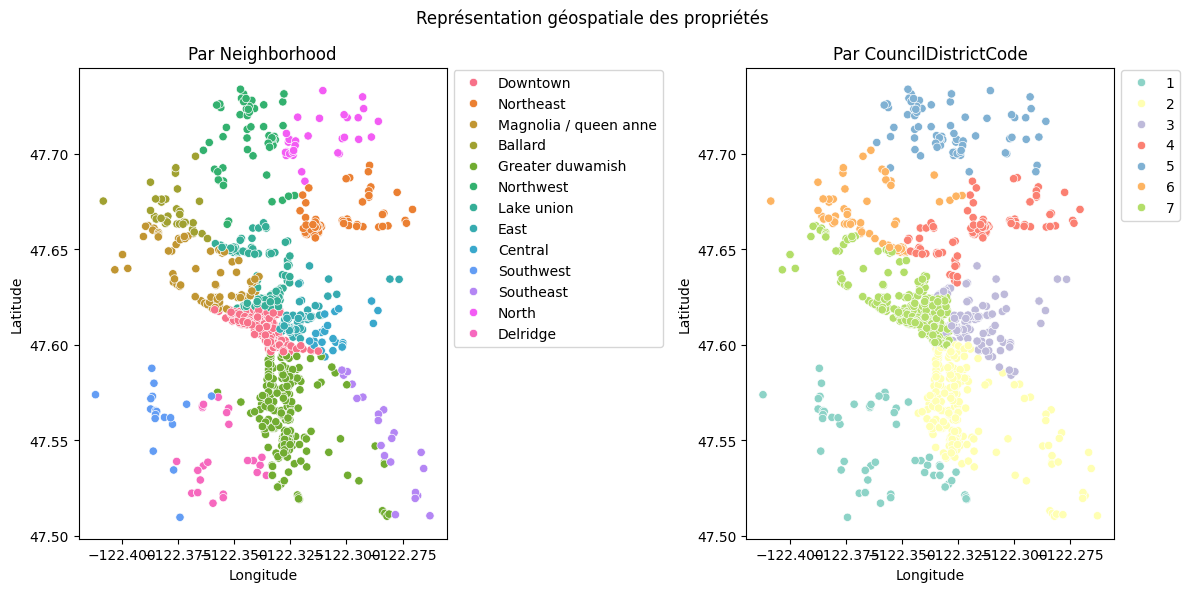

In [65]:
# Initialisation de la figure
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Premier scatterplot
sns.scatterplot(x='Longitude', y='Latitude', data=Data_3, hue='Neighborhood', ax=ax[0])
ax[0].set_title('Par Neighborhood')
ax[0].legend(bbox_to_anchor=(1, 1.01), loc="upper left")

# Deuxième scatterplot
sns.scatterplot(x='Longitude', y='Latitude', data=Data_3, hue='CouncilDistrictCode', palette='Set3', ax=ax[1])
ax[1].set_title('Par CouncilDistrictCode')
ax[1].legend(bbox_to_anchor=(1, 1.01), loc="upper left")

# Ajout d'un titre
fig.suptitle('Représentation géospatiale des propriétés ')

# Ajustement de la figure
plt.tight_layout()

# Sauvegarde de la figure
plt.savefig(f'../Output/Analyses exploratoires/Analyses bivariées/Distribution des valeurs de longitude et latitude en fonction des groupes géographiques.png', format='png')

# Affichage de la figure
plt.show()

Les deux variables montrent une répartion cohérente des propriétés selon leur localisation géospatiale et selon les catégories de Neighborhood et de CouncilDistrictCode.
La variable Neighborhood étant plus précise et n'ayant pas trop catégories, ni de catégorie à faible effectif sera conservée et la variable CouncilDistricCode ne sera pas prise en compte pour l'étape de modélisation.

In [66]:
# Ajout des nouvelles variables à retirer dans la liste des variables à exclure
Features_to_remove = Features_to_remove + ['CouncilDistrictCode', 'Longitude', 'Latitude']

# Feature engineering 

## Proportion de chaque type d'énergie

Une information qui pourrait être intéressante d'inclure dans le modèle est la porportion d'utilisation de chacun des types d'énergie. On peut donc calculer la proportion de chaque type d'énergie. Toutefois, comme ces informations ne seront peut être  pas accessibles lors de la construction d'une nouvelle propriété il ne faudra pas utiliser ces nouvelles variables directement car elles ne seront pas présentes dans le jeu de données de propriétés pour lesquelles on souhaite prédire la consommation énergétique et les émissions de gaz. En revanche, il peut être intéressant de calculer une moyenne de ces nouvelles variables pour chacune des catégories de PrimaryPropertyType sur le jeu d'entrainement au sein d'une pipeline et d'attribuer les moyennes calculées au jeu de données non vu par le modèle avec une méthode transforme.

In [67]:
# Construction des variables correspondant aux proportion d'utilisation des différents type d'énergie
Data_3['SteamUse_prop']= Data_3['SteamUse(kBtu)']/ Data_3['SiteEnergyUse(kBtu)']
Data_3['Electricity_prop']= Data_3['Electricity(kBtu)']/ Data_3['SiteEnergyUse(kBtu)']
Data_3['NaturalGaz_prop']= Data_3['NaturalGas(kBtu)']/ Data_3['SiteEnergyUse(kBtu)']

## Type de rue 

Nous avons vu que la variable adresse était trop complexe car trop spécifique à chaque propriété. Néanmoins de l'information peut être extraite de cette variable comme le type de rue sur lequel se trouve une propriété: Street, Avenue, Way... 

Pour créer cette nouvelle variable, nous allons créer un dictionnaire contenant des mots clés à rechercher dans les adresses. Pour éviter que la recherche de pattern capture des noms de rue contenant un St ou Ste correspondant à Saint ou Sainte, ces cas ne seront pas pris en compte.

In [68]:
# Création d'un dictionnaire des catégories et mots-clés
categories_keywords = {
    "Street": [" Street", " ST", " ST."], 
    "Avenue": [" Avenue", " Av", " Ave"],
    "Way": [" Way"]}

# Création de la nouvelle colonne "TypeStreet"
Data_3["StreetType"] = "other"

# Parcours des catégories
for categorie, keywords in categories_keywords.items():
    # Création du pattern avec des groupes non capturants
    escaped_keywords = [re.escape(k) for k in keywords]
    
    # Création d'un pattern s'assurtant que les mots-clés sont bien séparés par des espaces ou soient présents à la fin de la chaîne
    pattern = r"(?:\b(?:{})\b)".format("|".join(escaped_keywords))
    
    # Création du masque (toutes les lignes qui correspondent au pattern)
    mask = Data_3["Address"].str.contains(pattern, case=False, na=False) & ~Data_3["Address"].str.contains(r"\bSaint\b|\bSte\b", case=False, na=False)
    
    # Attribution de la catégorie pour ces lignes
    Data_3.loc[mask, "StreetType"] = categorie

# Visualisation du nombre de valeurs par catégorie de cette nouvelle variable
Data_3['StreetType'].value_counts()

StreetType
Avenue    575
Street    221
Way       117
other      60
Name: count, dtype: int64

## Batiments 1 vs >1 

Lors de l'analyse univarié nous avions également remarqué que la variable NumberofBuilding telle quelle était peu informative car la majorité des propriété possédait qu'un seul bâtiment. Pour chaque nombre de bâtiments supérieur à 1, on n'avait qu'une ou deux propriétés au maximum. Un moyen de contouner ce problème serait de regrouper toutes les propriétés avec plus d'un bâtiment ensemble dans une variable binaire qui prendrait True si une propriété a plus d'un bâtiment ou False sinon.

In [69]:
# Construction de la variable MoreThanOneBuilding
Data_3['MoreThanOneBuilding'] = Data_3['NumberofBuildings']>1

## Surface

Une autre idée serait de créer de nouvelles variables liées à la surface comme une variable correspondant à la surface par étage.

In [70]:
# Construction de la variable GFAbyfloor
Data_3['GFAbyfloor']=(Data_3['PropertyGFABuilding(s)']) / (Data_3['NumberofFloors'].astype(int))

## Age propriété

Un autre point important concerne la variable YearBuilt. Les nouvelles propriétés qui seront construites après la mise en place du modèle auront une date de construction que le modèle n'aura jamais vue pendant la phase d'entrainement. Pour contourner ce problème on peut transformer cette variable en calculant l'âge de la propriété. Cette nouvelle variable, l'âge de la propriété, est plus générique et peut être utilisée indépendamment de l'année exacte de construction, ce qui permet au modèle de mieux s'adapter aux nouvelles propriétés construites après la mise en place du modèle.

In [71]:
# Construction de la variable AgeBuilding
Data_3['AgeBuilding'] = 2016 - Data_3['YearBuilt'] 

## Nombre de type d'usage

Enfin il est également possible d'extraire de l'information d'une autre variable écartée en début de projet et qui contient la liste de tous les usages associés à la propriété. On pourrait par exemple extraire le nombre d'usages associés à chaque propriété et le sauvegarder dans une nouvelle variable. Cette variable reflète la complexité fonctionnelle des proppriétés et pourrait aider le modèle à tirer partie de cette nouvelle information. 

In [72]:
# Calcul du nombre d'usages associés à chaque propriétés
Data_3['nUseType'] = Data_3['ListOfAllPropertyUseTypes'].str.count(",")+1

## Nouvelles features

In [73]:
# Ajout des nouvelles variables construite dans la liste contenant les features candidates
Candidate_features = Candidate_features + ['StreetType', 'Electricity_prop', 'NaturalGaz_prop', 
                                            'SteamUse_prop', 'GFAbyfloor',
                                          'MoreThanOneBuilding', 'AgeBuilding', 'nUseType']

# Ajout d'une nouvelle variable à retirer dans la liste des variables à exclure
Features_to_remove = Features_to_remove + ['YearBuilt', 'NumberofBuildings']

<Figure size 800x600 with 0 Axes>

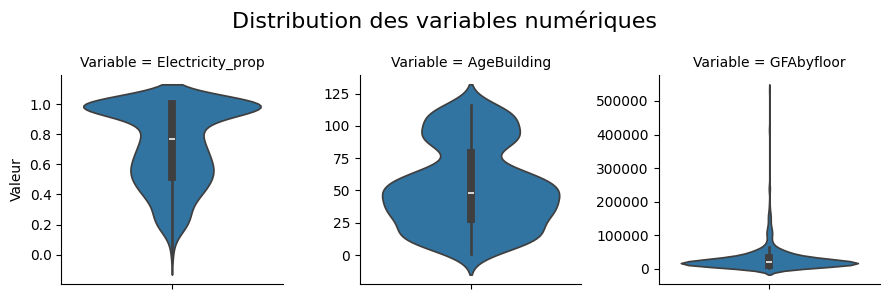

In [74]:
# Définition des variables à analyser
Analysed_features = ['Electricity_prop',  'AgeBuilding', 'GFAbyfloor' ]

# Apppel de la fonction
dist_grid(Data_3, Analysed_features, sns.violinplot,3, "explicatives construites")

On note que la variable correspondant aux surfaces par étage a une distribution asymétrique. Il faudra le prendre en compte pendant la phase de modélisation car certains modèles peuvent être sensibles et moins adaptés à ce type de distributions. Des stratégies de préprocessing pourront être mises en place pour y remédier.

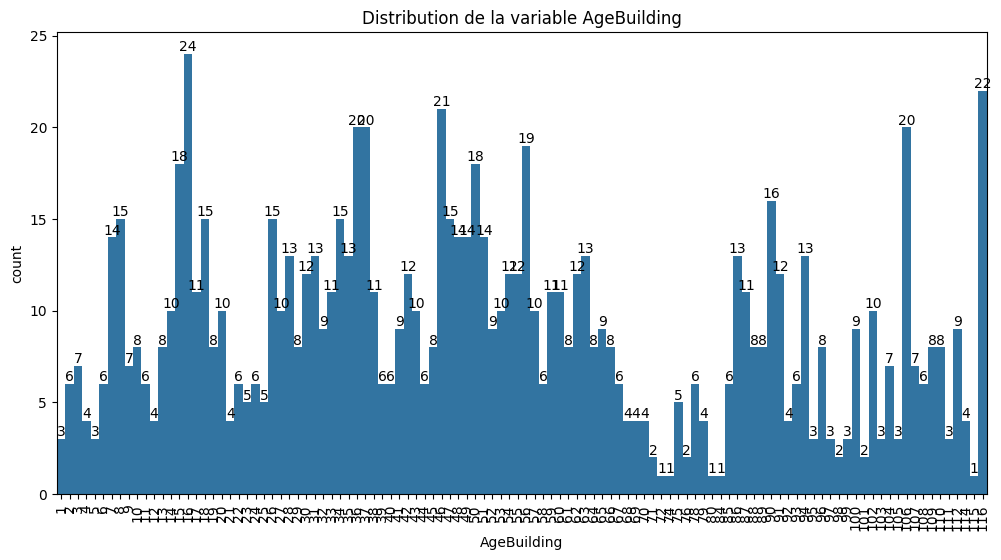

In [75]:
# Analyse de la distribution de la variable NumberofBuildings
Selected_Features = 'AgeBuilding'
countplot_var(Data_3, Selected_Features, figsize=(12, 6), label_rotated = True)

La distribution de l'âge des propriété reflète celle observée pour l'année de construction et montre la présence de propriétés récentes construites il y a moins de 10 ans et de propriétés plus anciennes construites il y a plus de 100 ans. 

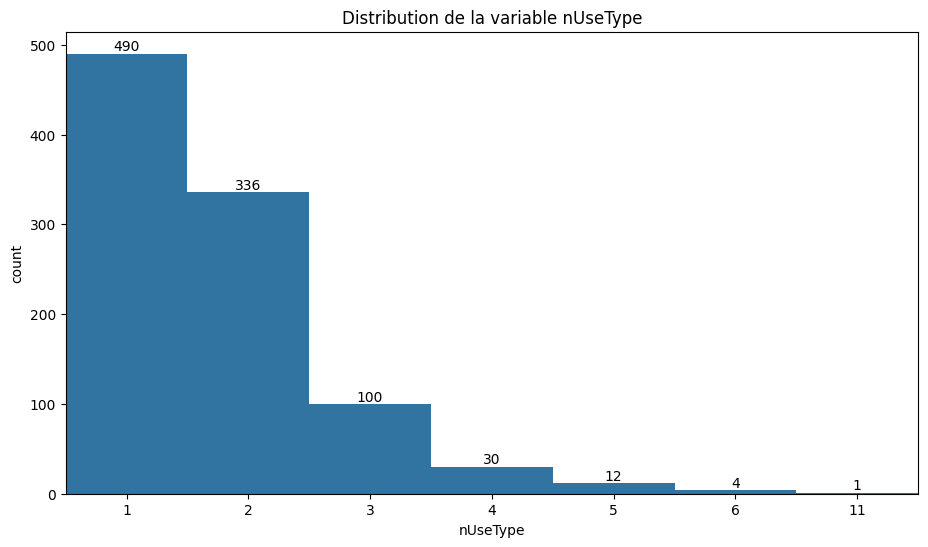

In [76]:
# Analyse de la distribution de la variable nUseType
Selected_Features = 'nUseType'
countplot_var(Data_3, Selected_Features, figsize=(11, 6))

Environs la moitié des propriétés ont un seul type d'usage qui leur est associée. L'autre moitié en a de 2 jusqu'à 11.

# Deuxième analyse des données

## Relation entre les variables cibles et les variables prédictives 

### Fonctions utiles

In [77]:
def scatter_grid_var_pred_cib(df, features, figsize=(15, 6)):
    
    """
    Affiche une grille de graphiques de dispersion entre les deux variables cibles et une variable explicative.
    
    La fonction crée un scatter plot pour chaque variable cible sélectionnée
    (par exemple les consommations et émissions), afin d'analyser visuellement
    la relation entre la variable prédictive et chacune des cibles.

    Paramètre
     - df (pandas.DataFrame): DataFrame contenant les données à visualiser. Doit inclure les colonnes
    'OSEBuildingID', 'TotalGHGEmissions' et 'SiteEnergyUse(kBtu)'.
     - features (str): Nom de la variable explicative à afficher sur l'axe des abscisses.
     - figsize (tuple of int, default=(15, 6)): Dimensions finales de la figure matplotlib (largeur, hauteur).
    """

    # Copie de la dataframe
    Df_scatter = df.copy()

    # Sélection des variables que l'on souhaite visualiser dans les boxplots
    Df_scatter = Df_scatter[[features] + ['OSEBuildingID', 'TotalGHGEmissions', 'SiteEnergyUse(kBtu)']]

    # Reformatage de la table pour pouvoir visualiser les boxplots en grille
    Df_scatter = Df_scatter.melt(id_vars=[features] + ['OSEBuildingID'],
                                  var_name="Variable", value_name="Valeur")

    # Création des scatter plots
    plt.figure(figsize=(12, 6))  
    g = sns.FacetGrid(Df_scatter, col="Variable", col_wrap=3, sharey=False, height=8, aspect=4)
    g.fig.set_size_inches(figsize[0], figsize[1])  
    g.map(sns.scatterplot, features, "Valeur",  alpha=0.7, s=70)
    
    # Ajustement de la taille des titres et labels
    g.set_titles(size=20) 
    g.set_axis_labels(features, "Valeur", size=20)  

    # Modification de la taille des graduations
    for ax in g.axes.flat:
        ax.tick_params(labelsize=20)  
    
    # Ajustement de la figure
    plt.tight_layout()
    
    # Sauvegarde de la figure
    plt.savefig(f'../Output/Analyses exploratoires/Analyses bivariées/Distribution des valeurs des variables cibles en fonction des groupes de la variable {features}.png', format='png')

    # Affichage du graphique
    plt.show()

In [78]:
def boxplot_grid_var_pred_cib(df, feature, figsize=(20, 10), showfliers=True):
    
    """
    Affiche une grille de boxplots représentant la distribution des deux variables
    cibles en fonction d'une variable catégorielle explicative.

    Chaque graphique montre la distribution d'une variable cible (ex. consommation
    énergétique, émissions de GES) pour chaque modalité de la variable explicative,
    permettant de comparer les distributions entre catégories.

    Paramètres
     - df (pandas.DataFrame): DataFrame contenant les données à visualiser. Doit inclure les colonnes
     'OSEBuildingID', 'TotalGHGEmissions' et 'SiteEnergyUse(kBtu)'.
     - feature (str): Nom de la variable catégorielle utilisée pour regrouper les observations
     (affichée sur l'axe des abscisses).
     - figsize (tuple of int, default=(20, 10)): Dimensions de la figure matplotlib (largeur, hauteur).
     - showfliers (bool, default=True):Indique si les valeurs aberrantes (outliers) doivent être affichées 
     ans les boxplots.
    """
    
    # Copie des données 
    Df_boxplot = df.copy()

    # Sélection des variables à visualiser
    Df_boxplot = Df_boxplot[[feature, 'OSEBuildingID', 'TotalGHGEmissions', 'SiteEnergyUse(kBtu)']]

    # Reformatage de la table
    Df_boxplot = Df_boxplot.melt(id_vars=[feature, 'OSEBuildingID'],
                                 var_name="Variable", value_name="Valeur")
    
    # Création d'une palette de couleurs
    n_categories=Df_boxplot[feature].nunique()
    palette = sns.color_palette("Set3", n_colors=n_categories)
    
    if n_categories<20:
        # Création des FacetGrid avec boxplots
        plt.figure(figsize=(12, 10))  
        g = sns.FacetGrid(Df_boxplot, col="Variable", col_wrap=2, sharey=False, height=6, aspect=1.5)
    else:
        g = sns.FacetGrid(Df_boxplot, col="Variable", col_wrap=1, sharey=False, height=6, aspect=1.5)
    g.map_dataframe(
        sns.boxplot,
        x=feature,
        y="Valeur",
        hue=feature,  
        showfliers=showfliers,
        palette="Set3",
        legend=False             
    )
    # Ajustement des titres et labels
    g.set_titles(size=20)
    g.set_axis_labels(feature, "Valeur", size=20)

    # Rotation des graduations
    for ax in g.axes.flat:
        ax.tick_params(labelsize=20)
        for label in ax.get_xticklabels():
            label.set_rotation(90)

    # Ajustement de la figure
    plt.tight_layout()
    
    # Sauvegarde de la figure
    plt.savefig(f'../Output/Analyses exploratoires/Analyses bivariées/Distribution des valeurs des variables cibles en fonction des groupes de la variable {feature}.png', format='png')

    # Affichage du graphique
    plt.show()

### Variable cible vs variable quantitative 

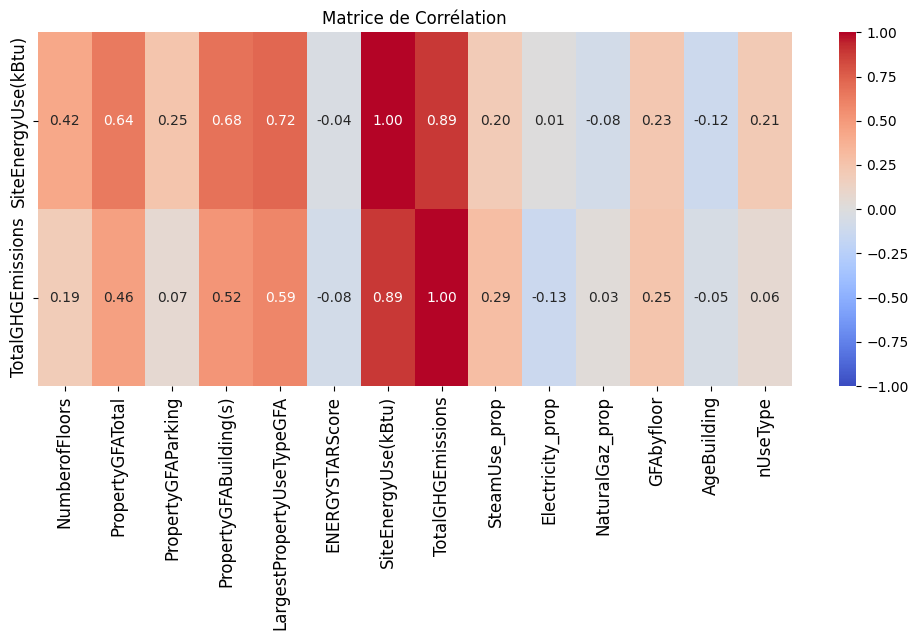

In [79]:
# Définition des variable à analyser
Analysed_features = [col for col in Data_3.columns 
                  if Data_3[col].dtype in ['float64', 'int64'] and  col not in Features_to_remove]

# Ajout des variable cibles
Analysed_features = Analysed_features 

# Normalisation des données
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(Data_3[Analysed_features])

# Conversion des données normalisée en dataframe
Data_df = pd.DataFrame(X_scaled, columns=Analysed_features)

# Construction d'une matrice de corrélation des variables
corr_matrix =Data_df.corr()

# Filtre pour ne garder que les lignes associées aux variables cibles
corr_matrix = corr_matrix.loc[[Variable_cible1, Variable_cible2]]

# Construction d'une heatmap représentant les corrélations des différentes variables avec les deux variables cibles
plt.figure(figsize=(10, 6.5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matrice de Corrélation')
plt.yticks(fontsize=12)
plt.xticks(rotation=90, fontsize=12)
plt.tight_layout()
plt.savefig(f'../Output/Analyses exploratoires/Corrélations/Corrélations entre les variables explicatives et les variables cibles.png', format='png')
plt.show()

L'analyse de la matrice des corrélations indique qu'aucune variable n'est parfaitement corrélée aux deux variables cibles ce qui justifie le reccours à un processus de modélisation par apprentissage automatique. Les coéfficients de corrélations observés sont hétérogènes, ce qui suggère que certaines variables pourraient avoir plus de poids dans un modèle de regression linéaire que d'autres. Si le choix du modèle se porte sur une régression linéaire, il sera probablement pertinent d'utiliser une technique de selection de variable ou d'utiliser une approche de régularisation permettant de pondérer l'influence des variables les plus pertinantes. On peut étudier ces corrélation plus visuellement à l'aide de représentation en nuage de points. On va prendre l'exemple d'une variable bien corrélée aux variables cibles et l'exemple d'une variable peu corrélée.

<Figure size 1200x600 with 0 Axes>

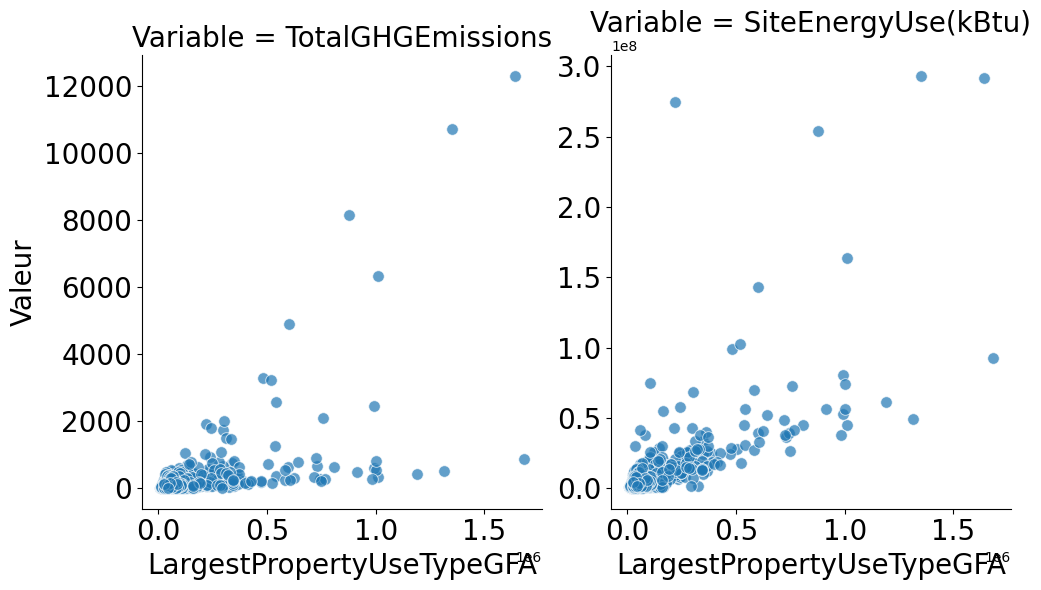

In [80]:
# Visusalisation des valeurs des deux variables cibles en fonction de la surface associé à l'usage principal des propriétés
scatter_grid_var_pred_cib(Data_3, 'LargestPropertyUseTypeGFA')

La surface associée au type d'usage principal des propriété est la variable la plus corrélée au variable cible selon le calcul du coefficient de corrélation. Quand on représente les valeurs des émissions en gaz a effet de serre en fonction des valeurs de cette variable on observe que dans l'ensemble, les propriété avec les plus petites valeurs de surface ont des émissions en gaz a effet de serre basse. Les valeurs les plus élevées en émissions en gaz a effet de serre sont obtenues pour les propriétés ayant des surfaces plutôt élevées comparativement au reste du jeu de données. On note toutement qu'on a également des propriétés de surface importante avec des valeurs d'émissions en gaz a effet de serre plutôt faible ce qui explique le coefficient de corrélation plutôt modéré identifié à l'étape précédente.

Concernant les consommations énergétique on observe une meilleure corrélation visuellement ce qui confirme ce qui a été observé avec le coéfficient de corrélation. En effet, mis a par pour une propriété qui a une surface faible associée a une consomation énergétique élevée, on remarque que plus la surface est élevée plus les consommations énergétiques sont également élevée. 

<Figure size 1200x600 with 0 Axes>

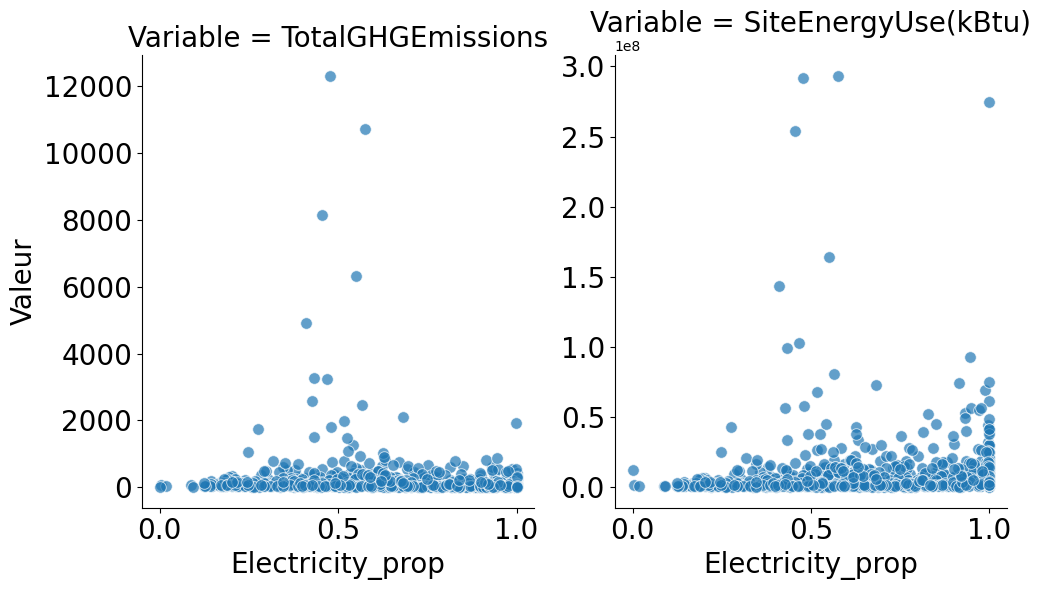

In [81]:
# Visusalisation des valeurs des deux variables cibles en fonction de la proportion de consommation de l'élétricité
scatter_grid_var_pred_cib(Data_3, 'Electricity_prop')

Ici, on a représenté une des variables les moins corrélées avec les variables cibles et on peut noter qu'en effet, il ne semble pas y avoir de relation linéaires entre les variables cible et cette variable. Pour les émissions en gaz a effet de serre, les valeurs les plus élevées correspondent à des valeurs de proportion de consommation d'électricité intermédiaire.
On peut également représenter la variable ENERGYSTARscore en fonction des variables cibles. 

Pour la consommation énergétique, on note une distribution similaire des propriétés, en notant nénanmoins qu'on a une légère augmentation des consommations énergétiques lorsque les propriétés utilisent ou tendent a utiliser uniquement de l'éléctricité. 

<Figure size 1200x600 with 0 Axes>

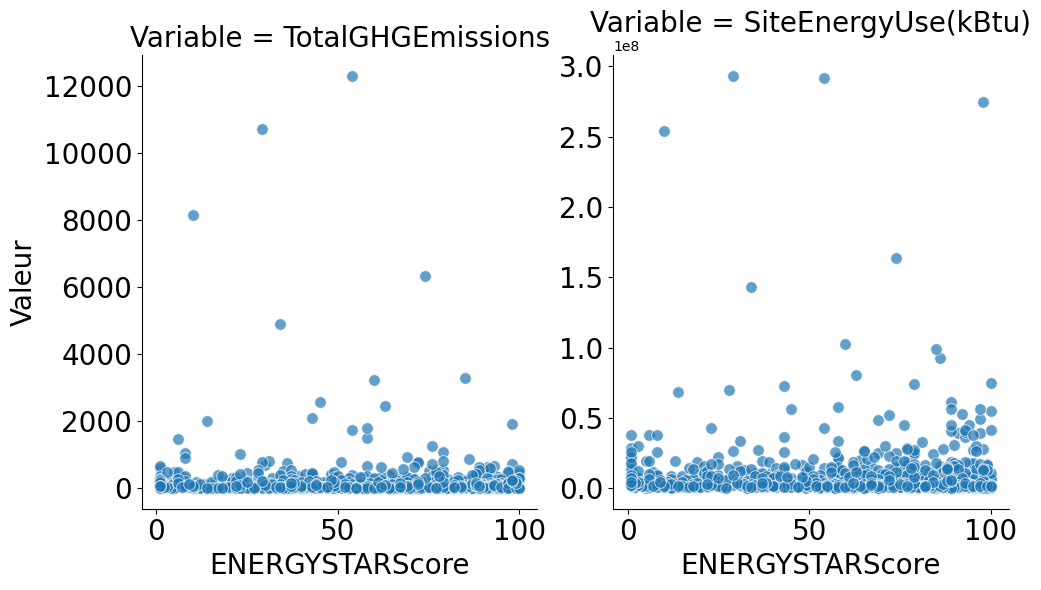

In [82]:
# Visusalisation des valeurs des deux variables cibles en fonction du score ENERGYSTAR
scatter_grid_var_pred_cib(Data_3, 'ENERGYSTARScore')

Ces deux graphiques représentent les consommations énergétiques en fonction de la variable ENERGYSTARscore et les émissions en gaz à effet de serre en fonction de cette même variable.
Comme l'indiquait le coefficient de corrélation, on ne remarque pas de relation linéaire entre la variable ENERGYSTARscore et les deux variables cibles. Le score ENERGYSTAR étant calculé à partir des consommations énergétique, un lien doit bien exister entre ces deux variables mais celui ci n'apparait pas linéaire. 

### Variable cible vs variable qualitative

<Figure size 1200x1000 with 0 Axes>

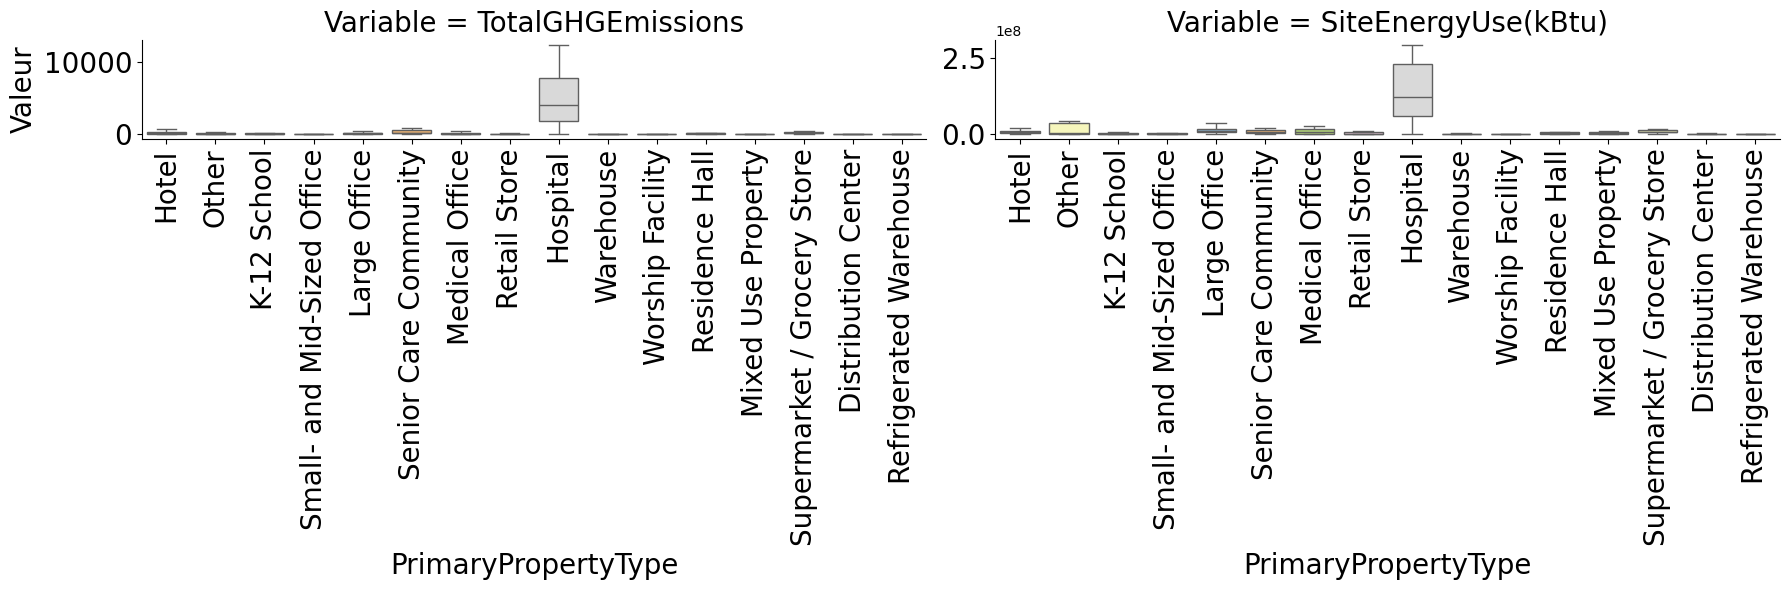

In [83]:
# Visusalisation des valeurs des deux variables cibles en fonction des types de propriétés
boxplot_grid_var_pred_cib(Data_3,  'PrimaryPropertyType', showfliers=False)

L'étude de ces graphique permet de montrer que les consommations énergétiques ainsi que les émissions en gaz à effet de serre sont différentes selon le type de propriétés considéré. On remarque nottament des valeurs très élevées pour ces deux variables dans le cas des hôpitaux mais il faut aussi noter que ces derniers ont des valeurs hautement variables. On note égalemet la présence de certains type de propriétées pour lesquelles les émissions en gaz à effet de serre et les consommations énergétiques sont plus basses que pour d'autres types de propriété et peu variables. C'est le cas des écoles, des entrepôts et des lieux de culte par exemple. La variable contenant un nombre de catégorie assez important, il pourrait être intéressant de regrouper certaines d'entre elles.

<Figure size 1200x1000 with 0 Axes>

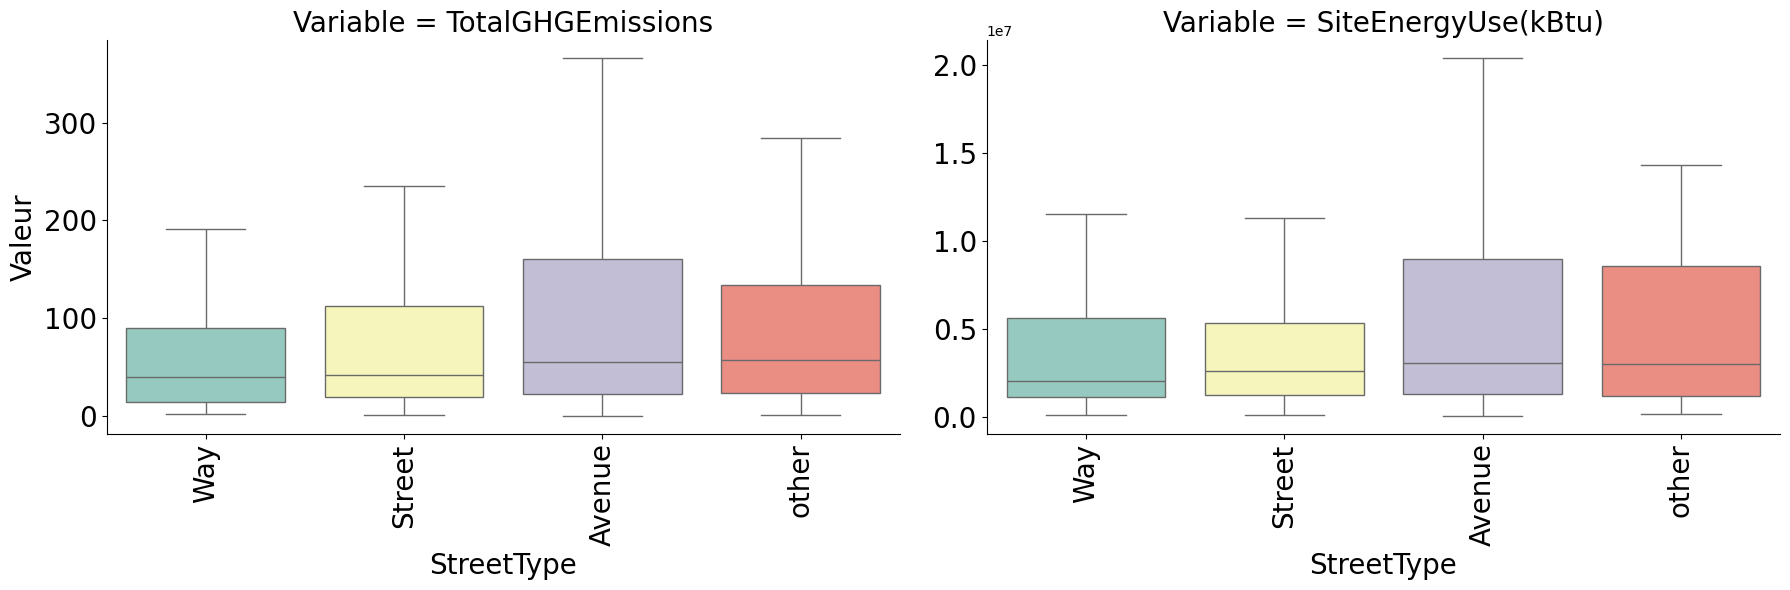

In [84]:
# Visusalisation des valeurs des deux variables cibles en fonction des types de rue
boxplot_grid_var_pred_cib(Data_3,  'StreetType', showfliers=False)

Ici on note une légèrement augmentation des émissions en gaz à effet de serre et des consommations énergétiques pour les propriétés situées sur des avenues ou sur des types de rues non déterminées par la variable construite mais les valeurs de ces groupes sont aussi très variables. Il n'apparait pas de tendance claire mais cette information peut par intéraction avec d'autres variables enrichir le modèle et être utile pour les prédictions.

<Figure size 1200x1000 with 0 Axes>

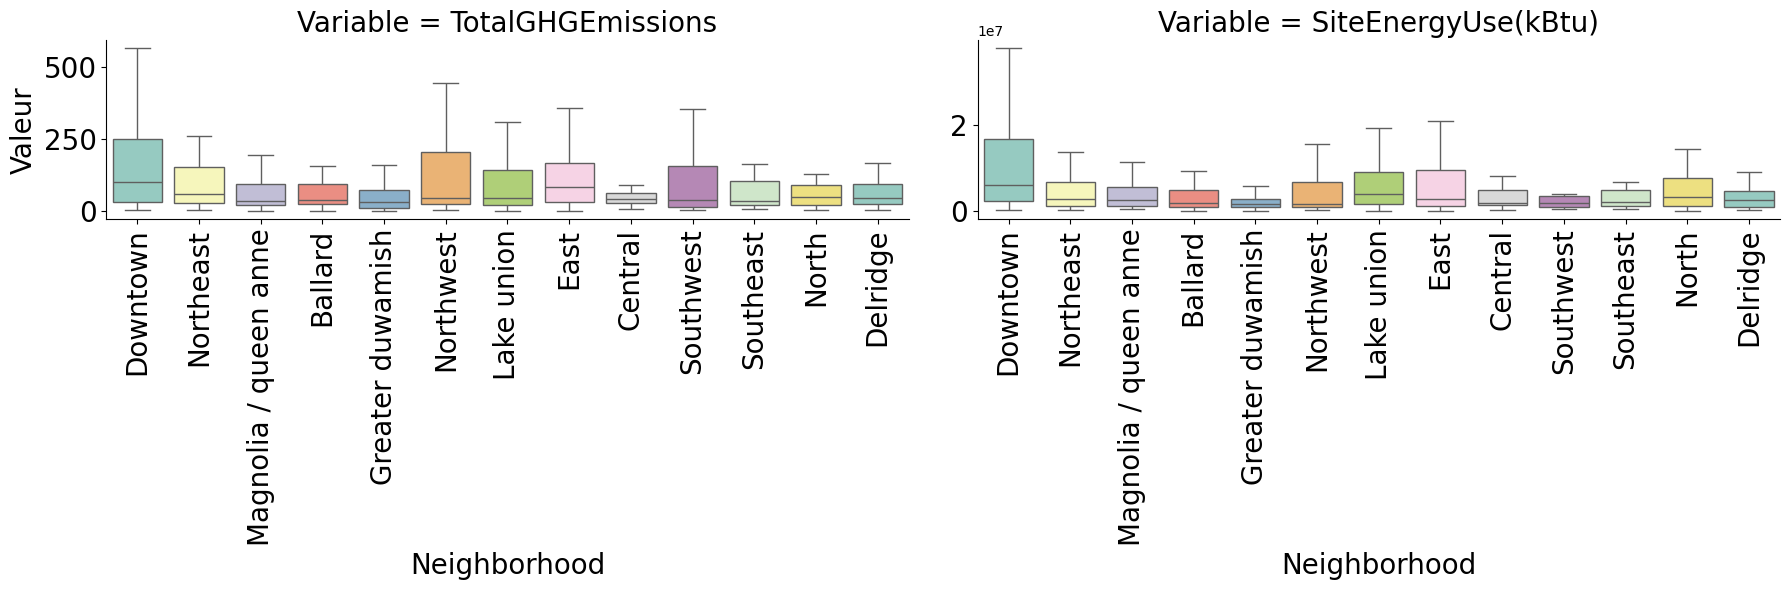

In [85]:
# Visusalisation des valeurs des deux variables cibles en fonction des quartiers
boxplot_grid_var_pred_cib(Data_3,  'Neighborhood',  showfliers=False) 

L'étude de ce graphique permet de voir que les valeurs des émissions en gaz à effet de serre et des consommations énergétiques se distribuent différement selon les quartiers. En particulier, dans le quartier centrale, les émissions en gaz à effet de serre se concentrent dans des valeurs un peu plus basses par rapport aux autres quartiers où on observe une plus grande variabilité et des émissions en gaz pouvant atteindre des valeurs plus élevées. De même pour les consommations énergétiques, on remarque le quartier Greater duwamish où on a des des valeurs plus basse et moisn variable par rapport aux autres quartiers.  

<Figure size 1200x1000 with 0 Axes>

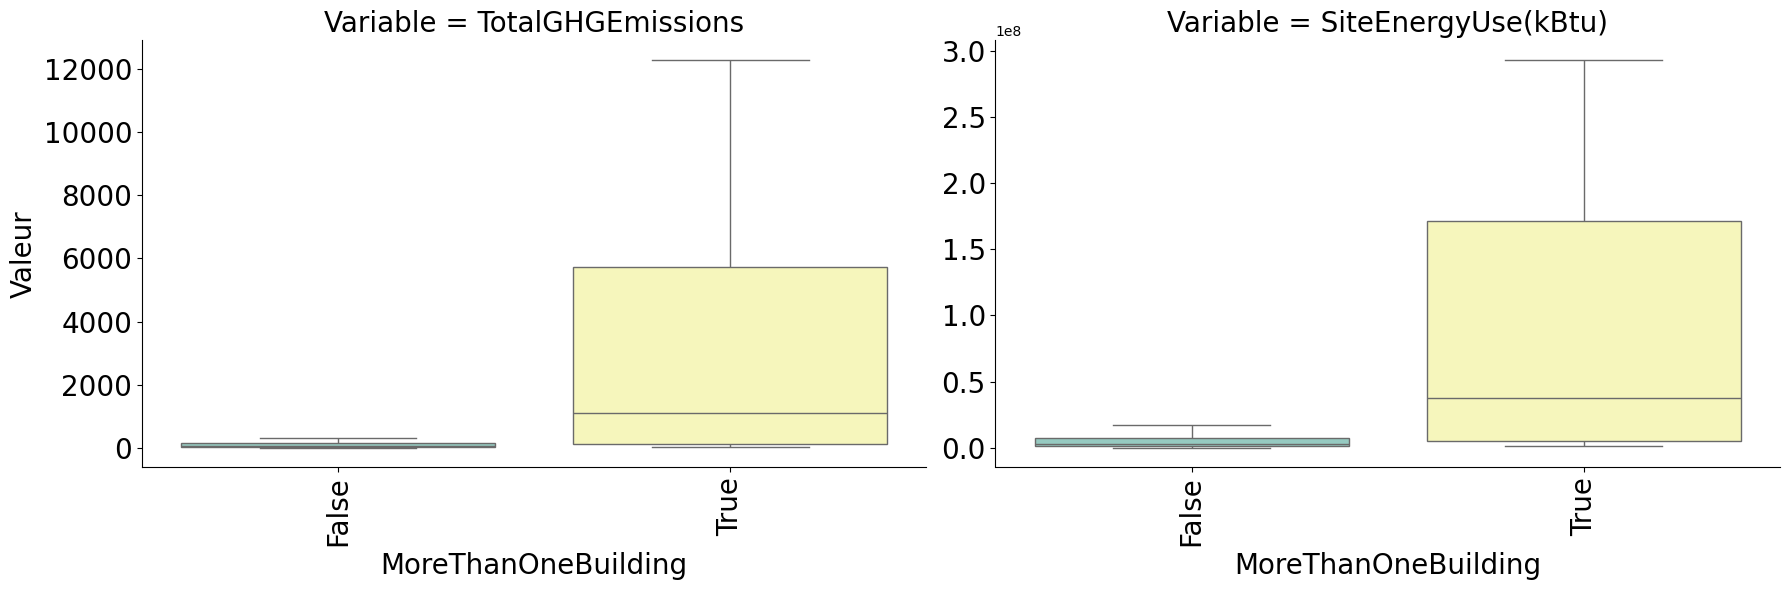

In [86]:
# Visusalisation des valeurs des deux variables cibles en fonction des groupes de propriété avec 1 ou plus de 1 bâtiments
boxplot_grid_var_pred_cib(Data_3,  'MoreThanOneBuilding',  showfliers=False) 

Ici, on remarque que les propriétés avec plus de 1 bâtiment ont des consommations énergététiques et des émissions en gaz à effet de serre globalement plus élevées que les propriétés avec uniquement 1 bâtiment

### Regroupement de catégories des variables liées au type d'utilisation

La variable PrimaryPropertyType contient un grand nombre de catégorie dont certaines ont des effectifs assez faible. Il pourrait être utile pour la modélisation de regrouper certaine catégories ensemble. Un des avantage de regrouper les catégorie à faible effectif ensemble est d'augmenter les chances que chaque catégories soit présentes dans les jeux de données d'entrainement, de test et de validation.

In [87]:
# Visualisation des effectifs des différentes catégories de la variable PrimaryPropertyType
Data_3['PrimaryPropertyType'].value_counts()

PrimaryPropertyType
Small- and Mid-Sized Office    232
Large Office                   160
Warehouse                      140
Hotel                           72
Retail Store                    72
Worship Facility                63
K-12 School                     49
Distribution Center             40
Supermarket / Grocery Store     39
Medical Office                  34
Mixed Use Property              24
Senior Care Community           18
Other                           11
Hospital                        10
Refrigerated Warehouse           5
Residence Hall                   4
Name: count, dtype: int64

La priorité sera de regrouper les entrepôts réfrigérés ainsi que les résidences universitaires ayant des effectifs très faible à d'autres catégories. Les résidences pourraient être regroupés avec les hotels dans une nouvelle catégorie qui regroupement toutes propriétés s'apparentant à un logement de personnes. On pourrait aussi regrouper les entrepôts réfrigérés avec les autres entrepôts et avec les centres de distribution. De même, toutes les propriétés s'apparentant à des magasins/point de ventes pourraient être regroupés ensemble. 

In [88]:
# Création de nouvelles catégories
Magasin = ['Supermarket / Grocery Store', 'Retail Store', 'Supermarket/Grocery Store']
Entrepot = ['Refrigerated Warehouse', 'Distribution Center', 'Warehouse']
Logement = ['Residence Hall', 'Hotel']
Administratif = ['Small- and Mid-Sized Office', 'Large Office']

# Modification des valeurs de la variable PrimaryPropertyType
Data_3.loc[Data_3['PrimaryPropertyType'].isin(Administratif), 'PrimaryPropertyType'] = "Administratif"
Data_3.loc[Data_3['PrimaryPropertyType'].isin(Magasin), 'PrimaryPropertyType'] = "Magasin"
Data_3.loc[Data_3['PrimaryPropertyType'].isin(Logement), 'PrimaryPropertyType'] = "Logement"
Data_3.loc[Data_3['PrimaryPropertyType'].isin(Entrepot), 'PrimaryPropertyType'] = "Entrepot"

In [89]:
# Viusalisation des effectifs des nouvelles catégories
Data_3['PrimaryPropertyType'].value_counts()

PrimaryPropertyType
Administratif            392
Entrepot                 185
Magasin                  111
Logement                  76
Worship Facility          63
K-12 School               49
Medical Office            34
Mixed Use Property        24
Senior Care Community     18
Other                     11
Hospital                  10
Name: count, dtype: int64

## Analyse des corrélations entre les variables quantitatives 

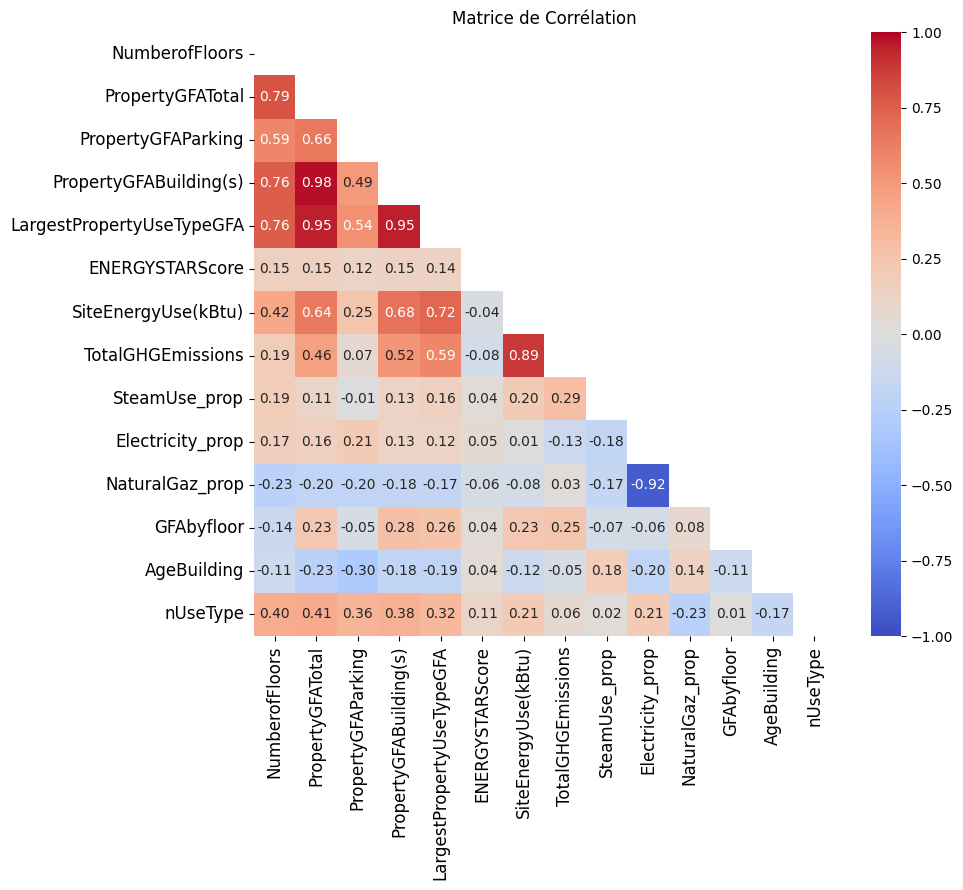

In [90]:
# Création d'une liste contenant les variables à analyser
Analysed_features = [col for col in Data_3.columns 
                  if Data_3[col].dtype in ['float64', 'int64'] and  col not in Features_to_remove]

# Normalisation des données
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(Data_3[Analysed_features])

# Conversion de la matrice obtenue après normalisation en Dataframe
Data_corr_matrice = pd.DataFrame(X_scaled, columns=Analysed_features)

# Construction d'une matrice de corrélation des variables
corr_matrix =Data_corr_matrice.corr()

# Définition d'un mask pour n'afficher que la diagonale inférieure de la matrice de corrélation
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Construction d'une heatmap représentant les corrélations des différents indicateurs
plt.figure(figsize=(10, 9))
sns.heatmap(corr_matrix, annot=True, mask=mask, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matrice de Corrélation')
plt.yticks(fontsize=12)
plt.xticks(rotation=90, fontsize=12)
plt.tight_layout()
plt.savefig(f'../Output/Analyses exploratoires/Corrélations/Corrélations entre les variables explicatives.png', format='png')
plt.show()

- Numberoffloors est fortement corrélé à 3 autres features : PropertyGFATotal, PropertyGFABuildings et LargestPropertyUseTypeGFA qui sont elles mêmes corrélées entre elles. On va dont exclure ces trois features représentant une surface. Il reste encore une feature représentant de la surface à savoir : GFAbyfloor
- NaturalGaz_prop est fortement corrélée a Electricity_prop. 

Nous allons donc l'exclure de l'analyse: **PropertyGFAtotal**, **PropertyGFAbuilding(s), LargestPropertyUseTypeGFA et NaturalGaz_prop**

In [91]:
# Ajout des nouvelles variables à retirer dans la liste des variables à exclure
Features_to_remove = Features_to_remove + ['PropertyGFATotal', 'PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA', 'NaturalGaz_prop']

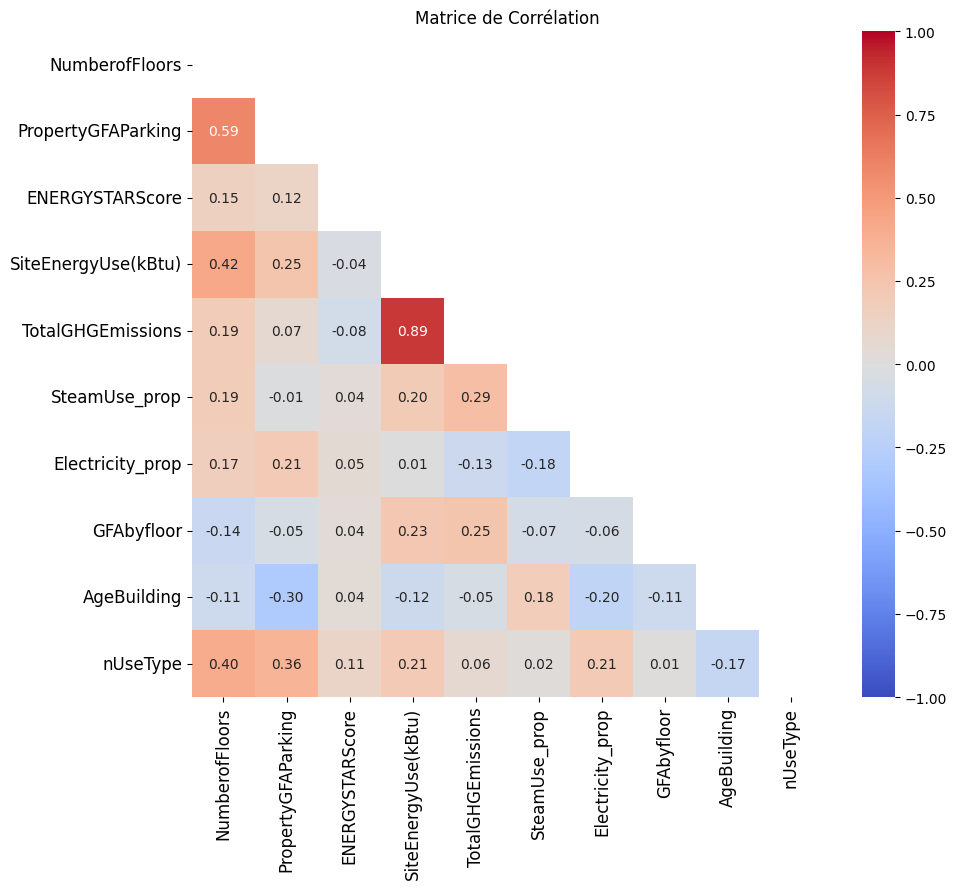

In [92]:
# Création d'une liste contenant les variables à analyser
Analysed_features = [col for col in Data_3.columns 
                  if Data_3[col].dtype in ['float64', 'int64'] and  col not in Features_to_remove]

# Normalisation des données
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(Data_3[Analysed_features])

# Conversion de la matrice obtenue après normalisation en Dataframe
Data_corr_matrice = pd.DataFrame(X_scaled, columns=Analysed_features)

# Construction d'une matrice de corrélation des variables
corr_matrix =Data_corr_matrice.corr()

# Définition d'un mask pour n'afficher que la diagonale inférieure de la matrice de corrélation
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Construction d'une heatmap représentant les corrélations des différents indicateurs
plt.figure(figsize=(10, 9))
sns.heatmap(corr_matrix, annot=True, mask=mask, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matrice de Corrélation')
plt.yticks(fontsize=12)
plt.xticks(rotation=90, fontsize=12)
plt.tight_layout()
plt.show()

Suite à l'analyse exploratoire plusieurs variables vont être retirées du jeux de données: 
- **variables peu informatives** : BuildingType, NumberofBuildings, PropertyName, Address, TaxParcelIdentificationNumber
- **variables fortement corrélées** : PropertyGFAtotal, PropertyGFAbuilding, SecondLargestPropertyTypeGFA, NaturalGaz_prop
- **variables catégorielles redondantes** : 'ZipCode, LargestPropertyUseYpe
- **variables entrainant de la fuite de données**: SiteEUI(kBtu/sf), SiteEUIWN(kBtu/sf), SourceEUI(kBtu/sf), SourceEUIWN(kBtu/sf), SiteEnergyUseWN(kBtu), SteamUse(kBtu), Electricity(kWh), Electricity(kBtu), 'NaturalGas(therms), NaturalGas(kBtu), GHGEmissionsIntensity

# Selection finale des features

In [93]:
# Visualisation de toutes les features à retirer
Features_to_remove

['PropertyName',
 'Address',
 'TaxParcelIdentificationNumber',
 'City',
 'State',
 'ListOfAllPropertyUseTypes',
 'OSEBuildingID',
 'Comments',
 'SiteEUI(kBtu/sf)',
 'SiteEUIWN(kBtu/sf)',
 'SourceEUI(kBtu/sf)',
 'SourceEUIWN(kBtu/sf)',
 'SiteEnergyUseWN(kBtu)',
 'SteamUse(kBtu)',
 'Electricity(kWh)',
 'Electricity(kBtu)',
 'NaturalGas(therms)',
 'NaturalGas(kBtu)',
 'GHGEmissionsIntensity',
 'ComplianceStatus',
 'DefaultData',
 'SecondLargestPropertyUseType',
 'SecondLargestPropertyUseTypeGFA',
 'ThirdLargestPropertyUseType',
 'ThirdLargestPropertyUseTypeGFA',
 'YearsENERGYSTARCertified',
 'Outlier',
 'DataYear',
 'ZipCode',
 'BuildingType',
 'LargestPropertyUseType',
 'CouncilDistrictCode',
 'Longitude',
 'Latitude',
 'YearBuilt',
 'NumberofBuildings',
 'PropertyGFATotal',
 'PropertyGFABuilding(s)',
 'LargestPropertyUseTypeGFA',
 'NaturalGaz_prop']

In [94]:
# Création d'une liste contenant les features à conserver pour l'étape de modélisation
Selected_Features = [element for element in Candidate_features if element not in Features_to_remove]

# Copie de la dataframe
Data_4 = Data_3.copy()

# Selection des features à conserver pour l'étape de modélisation
Data_4 = Data_4[Selected_Features]

# Visualisation de toutes les features conservées pour l'étape de modélisation
Selected_Features

['PrimaryPropertyType',
 'Neighborhood',
 'NumberofFloors',
 'PropertyGFAParking',
 'ENERGYSTARScore',
 'SiteEnergyUse(kBtu)',
 'TotalGHGEmissions',
 'StreetType',
 'Electricity_prop',
 'SteamUse_prop',
 'GFAbyfloor',
 'MoreThanOneBuilding',
 'AgeBuilding',
 'nUseType']

## Valeurs manquantes

In [95]:
# Visualisation du taux de valeurs manquantes par variable sur le jeu de données final
Data_4.isnull().mean()*100

PrimaryPropertyType    0.0
Neighborhood           0.0
NumberofFloors         0.0
PropertyGFAParking     0.0
ENERGYSTARScore        0.0
SiteEnergyUse(kBtu)    0.0
TotalGHGEmissions      0.0
StreetType             0.0
Electricity_prop       0.0
SteamUse_prop          0.0
GFAbyfloor             0.0
MoreThanOneBuilding    0.0
AgeBuilding            0.0
nUseType               0.0
dtype: float64

On remarque que les variables retenues pour l'analyse ne contiennent pas de valeurs manquantes.

In [96]:
# Visualisation du nombre d'observations et de variables retenues dans le jeu de données final
Data_4.shape

(973, 14)

In [97]:
# Saugarde des données
Data_4.to_csv("../Output/Analyses exploratoires/Table/Final_Data.csv", index=False)

# Conclusion

La première phase de ce projet à consisté à explorer et nettoyer le jeu de données. Cette étape exploratoire a permis d'identifier les variables les plus pertinentes pour la phase de modélisation en excluant celles jugées peu informatives, redondandes, ou non disponibles pour les futures propriétés. Cette étape a également permis de mieux comprendre les données, d'identifier et éventuellement corriger les données à priori anormales. Par ailleurs, plusieurs nouvelles caractéristiques ont été extraites à partir des données brutes par la création de nouvelles variables de façon à enrichir l'information injectée dans les modèles.  L'étape suivante consistera à modéliser les consommations énergétiques et les émissions en gaz à effet de serre à partir des variables retenues dans le but de construire des prédicteurs fiables et généralisables pour estimer les profils énergétiques des propriétées construites dans le futur.